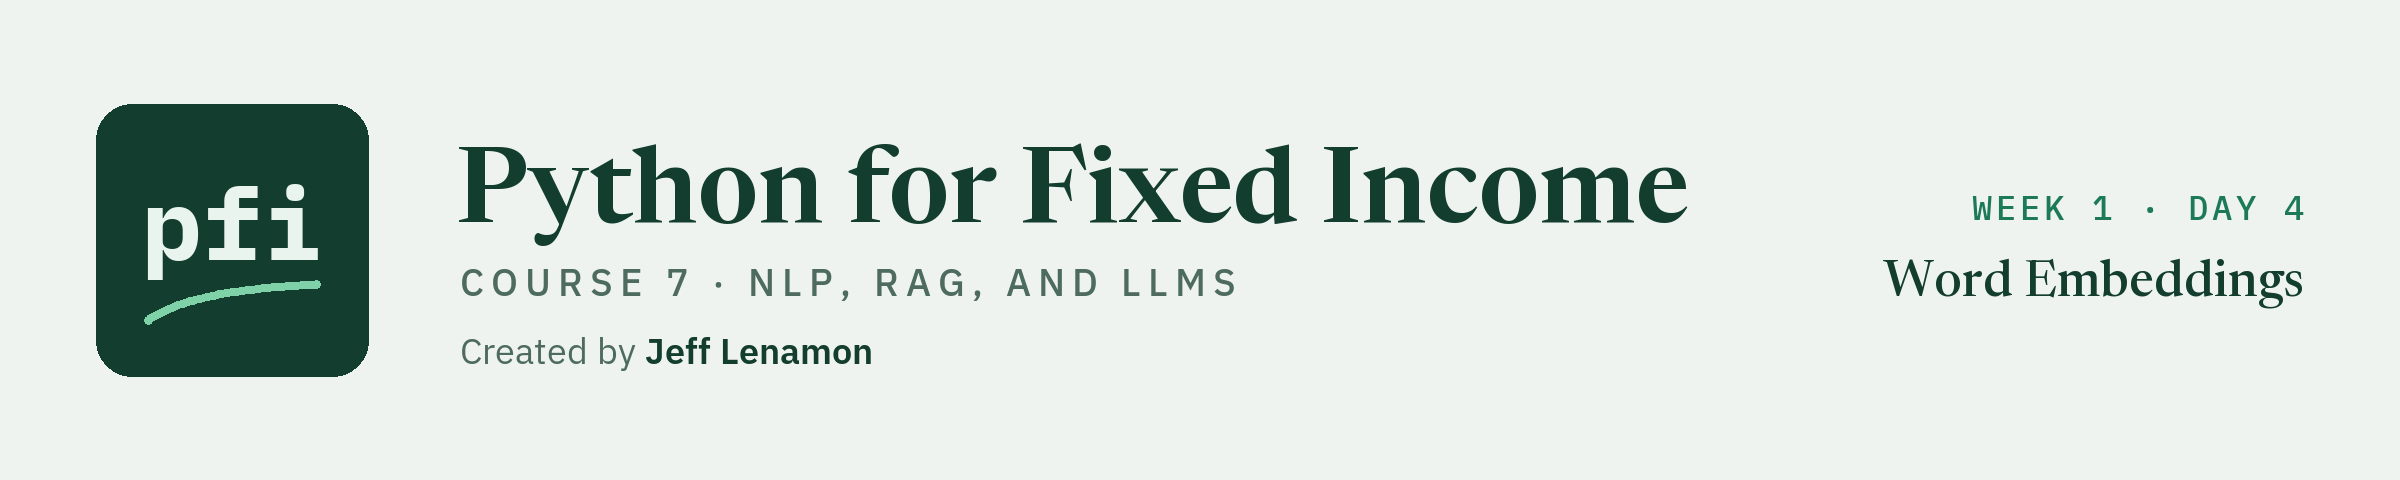

# Word Embeddings

Week 1, Day 4. Words as vectors: today you load pretrained word vectors, find a word's nearest neighbours, see what the vectors miss in an indenture, and turn 8-K sections into vectors for a classifier.

**Data:** `course7_glove_6b_100d.npz`, a subset of the GloVe 6B word vectors, 100 numbers per word: **real**, Pennington, Socher, and Manning (2014), https://nlp.stanford.edu/projects/glove/, Public Domain Dedication and License v1.0.

**Data:** `course7_8k_items.csv`, 5,126 item sections of Form 8-K current reports filed on EDGAR, 2019 to 2025, each labelled by the item its filer chose: **real**, public records (sec.gov), a sample drawn by the course (DATA.md).

**Data:** `course7_indentures/boyd_2021.txt`: Boyd Gaming Corporation, Indenture dated as of June 8, 2021, 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495: **real**, a public record on sec.gov, quoted for descriptive extraction only.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course7_nlp_and_llms/week1/day4/04_word_embeddings.ipynb)

Day 3 counted words: TF-IDF gives every term its own column, and two terms are as different as two columns can be, whatever they mean. "Bond" and "bonds" are two unrelated columns. Today each word becomes a short list of numbers learned from a large body of general English text, so that words used in the same contexts get numbers that point the same way. These are **word vectors**, also called word embeddings.

The vectors are GloVe's, trained by its authors at Stanford on Wikipedia 2014 and Gigaword 5 text. The course keeps 44,558 of their words in one file, 100 numbers each, read with numpy. No model is trained on the vectors today, and nothing is downloaded: the file is in the course's data folder.

Three documents run through the notebook: the vectors themselves; the Boyd Gaming indenture, to see which of its words the vectors know; and the 8-K item sections of day 3, to put the vectors to work as features.

**The rules for real documents, as on every day of this course.**

* **The documents are real.** The 8-K sections are public records on sec.gov, each labelled by the item its filer chose; a model's output on one is "the item the model assigns", never a signal or a credit view on the company. The indenture is a public record filed by its issuer, quoted exactly as published, with a source line under every excerpt.
* **Described, never judged.** An indenture's terms are reported as the indenture states them, never called loose or tight, and no sentence compares issuers. A word's nearest neighbours describe how the word was used in the GloVe authors' training text, not what it means in a contract.
* **Issuer names appear only as the authors of the documents being read**: in the data line, the source line, and here.

**Rows.** Every model on the 8-K sections in this notebook is fitted on the 3,650 sections filed from 2019 to 2023 and scored on the 741 sections filed in 2024, labelled validation; the 735 sections filed in 2025 are closed until day 10.

Today you will:

1. Load the vectors with `load_word_vectors` and look at one word's numbers.
2. Measure the cosine between two words, and list a word's nearest words with `nearest_words`.
3. Find the indenture's tokens that have no vector, and what lower case loses.
4. Do the famous arithmetic on vectors once, with its caution.
5. Turn each 8-K section into the mean of its word vectors with `document_vectors`, and fit a classifier on them beside day 3's TF-IDF model.
6. See what an average loses: word order and each word's weight.
7. Draw a map of words, and build small word vectors yourself from pair counts in the indenture.

Q. Set up today's work folder: the thread settings, the quiet-loading settings, the seed, the modules, and today's three data files.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course7_nlp_and_llms/requirements.txt
NEEDED = {
    "bs4": "beautifulsoup4==4.15.0",
    "huggingface_hub": "huggingface-hub==1.33.0",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "keras": "keras==3.15.1",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openai": "openai==3.26.0",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pydantic": "pydantic==2.13.5",
    "pypdf": "pypdf==6.19.0",
    "pypdfium2": "pypdfium2==5.14.0",
    "pytest": "pytest==9.1.1",
    "dotenv": "python-dotenv==1.2.4",
    "requests": "requests==2.34.2",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "sentence_transformers": "sentence-transformers==6.1.0",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "tensorflow": "tensorflow==2.21.0",
    "torch": "torch==2.14.1",
    "transformers": "transformers==5.19.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

28 packages checked, all present


In [2]:
# today's setup: thread settings, quiet model loading, the modules, the seed, the course data, a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These lines must run before numpy, pandas, scikit-learn, or PyTorch is imported: if you ran another cell first,
# restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

# the model libraries print download bars and notices; these lines must run before they are imported
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("sklearn", "scikit-learn"), ("torch", "torch"), ("transformers", "transformers"), ("sentence_transformers", "sentence-transformers"), ("openai", "openai"), ("pydantic", "pydantic"), ("bs4", "beautifulsoup4"), ("pypdf", "pypdf"), ("pypdfium2", "pypdfium2"), ("dotenv", "python-dotenv"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course7_nlp_and_llms/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scikit-learn": "1.9.1", "torch": "2.14.1", "transformers": "5.19.0", "sentence-transformers": "6.1.0", "openai": "3.26.0", "pydantic": "2.13.5", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name].split("+")[0] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "course7_fomc_statements.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course7_04_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["course7_glove_6b_100d.npz", "course7_8k_items.csv", "course7_indentures/boyd_2021.txt"]
for name in DATA_FILES:
    (work / name).parent.mkdir(parents=True, exist_ok=True)
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, torch 2.14.1, transformers 5.19.0, sentence-transformers 6.1.0, openai 3.26.0, pydantic 2.13.5, pytest 9.1.1
Work folder: pfi_course7_04_ty6c5cou, in your temp folder
Data files from the data folder of the course repo: course7_glove_6b_100d.npz, course7_8k_items.csv, course7_indentures/boyd_2021.txt
SEED = 42


Q. Write the earlier courses' modules today needs, unchanged: `mlkit.py`, `plotkit.py`.

* The same setup cell as every Course 7 notebook (day 1 explains each line). Today reads vectors from a file with numpy and runs no model, so no PyTorch line appears.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


In [4]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


Q. Write `textkit.py` and `test_textkit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [5]:
%%writefile textkit.py
"""textkit: text as data for fixed income, from a regular expression to a checked LLM extraction.

Written day by day in Python for Fixed Income, Course 7: NLP and LLMs.

Conventions, the same in every function:
- Text is normalized by normalize_text before it is counted, searched, or compared: Unicode NFC, a fixed map of
  look-alike characters (no-break space, non-breaking hyphen, curly quotes, dashes), one space for every run of
  white space, and one newline between paragraphs. Source files keep the text exactly as published.
- A token is a run of lower-case letters and digits, joined by single hyphens, apostrophes, or full stops
  (TOKEN_PATTERN): "mortgage-backed" and "4.750" are one token each, "1/4" is two. No stemming.
- Section numbers and 8-K item codes are text ("4.12", "2.04"), so "4.10" never becomes 4.1.
- Money is in US dollars as whole numbers of dollars (855_000_000); percentages are as the source writes them
  (15.0 means 15.0 percent); ratios are floats with the unit "x" (2.0 means 2.00 to 1.00).
- The seed is 42 wherever a function takes one.
- Every output describes what a document says. Nothing here is a forecast, a rating, or a credit view.
- Empty inputs, or inputs of the wrong shape, raise ValueError with a message that says what was wrong.
"""
import re  # regular expressions
import unicodedata  # Unicode normalization

import pandas as pd  # tables with labels

import mlkit  # Course 4's module, unchanged: the split checks and the description check

# one token: letters and digits, joined by single hyphens, apostrophes, or full stops
TOKEN_PATTERN = r"[a-z0-9]+(?:[-'.][a-z0-9]+)*"
# a section heading at the start of a line: "Section 4.12. Limitation on Indebtedness" or "SECTION 4.12"; the
# title, if any, starts with a capital letter or "[", so a cross-reference that starts a line ("Section 4.12(b)",
# "Section 4.13 or Section 4.19 of the Indenture") is not a heading
SECTION_PATTERN = (r"^[ \t]*(?:SECTION|Section)[ \t]+(?P<number>\d{1,2}\.\d{1,2})(?![\d(])\.?"
                   r"(?:[ \t]+(?P<title>[A-Z\[][^\n]*?))?[ \t]*(?:\.(?=[ \t]|$)|$)")
# look-alike characters and the plain character each becomes (COURSE7_SPEC.md, "Conventions")
CHARACTER_MAP = {
    "\u00a0": " ",  # no-break space
    "\u2010": "-",  # hyphen
    "\u2011": "-",  # non-breaking hyphen
    "\u2013": "-",  # en dash
    "\u2014": "-",  # em dash
    "\u2018": "'",  # left single quote
    "\u2019": "'",  # right single quote
    "\u201c": '"',  # left double quote
    "\u201d": '"',  # right double quote
}


def normalize_text(text: str) -> str:
    """Return text with look-alike characters made plain and white space tidied.

    Input: text, any string.
    Output: the text after three steps: Unicode NFC; each character of CHARACTER_MAP replaced by its plain form;
    every run of white space that holds a line break becomes one newline (a paragraph break), and every other run
    of white space becomes one space; no space or newline at either end.
    Convention: idempotent, so normalize_text(normalize_text(t)) == normalize_text(t). Run it on both sides of any
    comparison of text.
    Raises ValueError if text is not a string.
    """
    if not isinstance(text, str):
        raise ValueError(f"text must be a string, not {type(text).__name__}")
    # one code point per accented letter, then the fixed map
    text = unicodedata.normalize("NFC", text).translate(str.maketrans(CHARACTER_MAP))
    # a run of white space with a line break in it is a paragraph break; any other run is one space
    text = re.sub(r"[^\S\n]*\n\s*", "\n", text)
    text = re.sub(r"[^\S\n]+", " ", text)
    return text.strip()


def tokenize(text: str, lower: bool = True) -> list[str]:
    """Split text into tokens with TOKEN_PATTERN, after normalize_text.

    Inputs: text; lower, True to lower-case first (the course's default; GloVe and TF-IDF are lower case).
    Output: the tokens in the order they appear. With lower=False the pattern runs ignoring case and each token
    keeps its case. A text with no letter or digit gives an empty list.
    Convention: "mortgage-backed", "longer-term", "4.750", and "company's" are one token each; "1/4" is two
    ("1", "4"), because a slash is not a joiner. No stop words are removed and no word is stemmed.
    Raises ValueError if text is not a string.
    """
    text = normalize_text(text)
    if lower:
        return re.findall(TOKEN_PATTERN, text.lower())
    return re.findall(TOKEN_PATTERN, text, flags=re.IGNORECASE)


def find_sections(text: str, pattern: str = SECTION_PATTERN) -> pd.DataFrame:
    """Find the section headings of an indenture and where each section starts and ends.

    Inputs: text, the indenture after normalize_text (one paragraph per line); pattern, a regular expression run
    with re.MULTILINE that has the named groups number and title (title may be empty).
    Output: a DataFrame with one row per section, in the order of the text: number (text, "4.12"), title, start
    (the heading's first character), end (the next kept heading's start, or the end of the text).
    Convention: an indenture lists every section twice, once in the table of contents and once in the body, so for
    each number only the last heading is kept: the body's. A heading must start a line.
    Raises ValueError if no heading is found.
    """
    found = {}
    for match in re.finditer(pattern, text, flags=re.MULTILINE):
        # a later heading with the same number replaces an earlier one: the table of contents comes first
        found[match.group("number")] = (match.start(), (match.group("title") or "").strip())
    if not found:
        raise ValueError("no section heading found; check the pattern against one heading of the text")
    rows = sorted(((start, number, title) for number, (start, title) in found.items()))
    starts = [start for start, _, _ in rows] + [len(text)]
    return pd.DataFrame({"number": [number for _, number, _ in rows], "title": [title for _, _, title in rows],
                         "start": starts[:-1], "end": starts[1:]})


def defined_terms(text: str) -> pd.DataFrame:
    """Find every definition of the form "Term" means ... or "Term" has the meaning ...

    Input: text, for example Section 1.01 of an indenture; curly quotes are made straight by normalize_text first,
    so start values count characters of the normalized text.
    Output: a DataFrame with one row per definition, in the order of the text: term (without its quotes), start
    (the opening quote's position in the normalized text), kind ("means" or "has the meaning").
    Convention: a term starts with a capital letter or a digit. Duplicates are kept, so a term defined twice shows
    twice; count them with value_counts.
    Raises ValueError if text is not a string.
    """
    text = normalize_text(text)
    pattern = r'"(?P<term>[A-Z0-9][^"\n]{0,100}?)"\s+(?P<kind>means|has the meaning)\b'
    rows = [{"term": m.group("term"), "start": m.start(), "kind": m.group("kind")}
            for m in re.finditer(pattern, text)]
    return pd.DataFrame(rows, columns=["term", "start", "kind"])


import numpy as np  # arrays, from day 2


def term_counts(docs: list[str], vocabulary: list[str] | None = None) -> pd.DataFrame:
    """Count each term in each document: the bag of words.

    Inputs: docs, a list of texts; vocabulary, the terms to count, in the order wanted (None counts every token
    found, with the columns sorted alphabetically).
    Output: a DataFrame of whole numbers, one row per document (in input order) and one column per term; a term
    missing from a document counts 0.
    Convention: tokens come from tokenize (lower case, TOKEN_PATTERN), so on plain ASCII text the table equals
    CountVectorizer(token_pattern=TOKEN_PATTERN) on the same vocabulary.
    Raises ValueError if docs is empty.
    """
    if len(docs) == 0:
        raise ValueError("docs is empty")
    tokens = [tokenize(doc) for doc in docs]
    columns = list(vocabulary) if vocabulary is not None else sorted({t for doc in tokens for t in doc})
    position = {term: j for j, term in enumerate(columns)}
    counts = np.zeros((len(docs), len(columns)), dtype=np.int64)
    for i, doc in enumerate(tokens):
        for token in doc:
            if token in position:
                counts[i, position[token]] += 1
    return pd.DataFrame(counts, columns=columns)


def idf(doc_freq, n_docs: int) -> np.ndarray:
    """Inverse document frequency with scikit-learn's smoothing: ln((1 + n) / (1 + df)) + 1.

    Inputs: doc_freq, the number of documents each term appears in (an array of whole numbers); n_docs, the number
    of documents.
    Output: a float64 array, one weight per term. A term in every document gets 1.0, never 0; a rarer term gets
    more.
    Convention: equal to TfidfVectorizer(smooth_idf=True).idf_ (the default). The log is natural.
    Raises ValueError if doc_freq is empty, any df is below 0 or above n_docs, or n_docs is below 1.
    """
    df = np.asarray(doc_freq, dtype=np.float64)
    if df.size == 0 or n_docs < 1:
        raise ValueError("doc_freq must hold at least one term and n_docs must be at least 1")
    if (df < 0).any() or (df > n_docs).any():
        raise ValueError(f"every document frequency must be between 0 and n_docs ({n_docs})")
    return np.log((1.0 + n_docs) / (1.0 + df)) + 1.0


def tfidf_by_hand(counts, sublinear: bool = False) -> np.ndarray:
    """TF-IDF from a table of raw counts, each row scaled to length 1.

    Inputs: counts, documents by terms (an array or a DataFrame from term_counts); sublinear, True to use
    1 + ln(tf) in place of tf for every count above 0 (scikit-learn's sublinear_tf).
    Output: a float64 array of the same shape: term frequency times idf, then each row divided by its Euclidean
    length. A document with no counted term stays a row of zeros.
    Convention: equal to TfidfVectorizer on the same vocabulary within 1e-12 (smooth idf, l2 norm).
    Raises ValueError if counts is not two-dimensional or holds a negative count.
    """
    tf = np.asarray(counts, dtype=np.float64)
    if tf.ndim != 2 or tf.size == 0:
        raise ValueError("counts must be a non-empty table of documents by terms")
    if (tf < 0).any():
        raise ValueError("counts must not be negative")
    weights = idf((tf > 0).sum(axis=0), tf.shape[0])
    if sublinear:
        tf = np.where(tf > 0, 1.0 + np.log(np.where(tf > 0, tf, 1.0)), 0.0)
    matrix = tf * weights
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    # a zero row has length 0: divide by 1 instead, so it stays zero rather than becoming NaN
    return matrix / np.where(norms == 0, 1.0, norms)


def cosine_similarity_matrix(A, B=None) -> np.ndarray:
    """Cosine similarity of every row of A with every row of B (or of A with itself).

    Inputs: A and B, arrays of rows by features (B None means B = A).
    Output: a float64 array, rows of A by rows of B: the dot product of two rows divided by the product of their
    lengths, between -1 and 1. A row of zeros gives 0 with every row, never NaN.
    Convention: equal to sklearn.metrics.pairwise.cosine_similarity within 1e-12. A cosine is a measure of
    direction, not a probability.
    Raises ValueError if A or B is not two-dimensional or their numbers of columns differ.
    """
    A = np.asarray(A, dtype=np.float64)
    B = A if B is None else np.asarray(B, dtype=np.float64)
    if A.ndim != 2 or B.ndim != 2 or A.shape[1] != B.shape[1] or A.size == 0 or B.size == 0:
        raise ValueError("A and B must be non-empty tables with the same number of columns")
    norm_a = np.linalg.norm(A, axis=1, keepdims=True)
    norm_b = np.linalg.norm(B, axis=1, keepdims=True)
    return (A / np.where(norm_a == 0, 1.0, norm_a)) @ (B / np.where(norm_b == 0, 1.0, norm_b)).T


from sklearn.feature_extraction.text import TfidfVectorizer  # TF-IDF, from day 3
from sklearn.linear_model import LogisticRegression  # the classifier, from day 3
from sklearn.metrics import precision_recall_fscore_support  # per-label scores, from day 3
from sklearn.pipeline import Pipeline  # steps fitted together on training rows, from day 3

# the eight Form 8-K items in the course's file, with the titles of the SEC's Form 8-K
ITEM_TITLES = {
    "1.01": "Entry into a Material Definitive Agreement",
    "1.03": "Bankruptcy or Receivership",
    "2.02": "Results of Operations and Financial Condition",
    "2.03": "Creation of a Direct Financial Obligation or an Obligation under an Off-Balance Sheet Arrangement "
            "of a Registrant",
    "2.04": "Triggering Events That Accelerate or Increase a Direct Financial Obligation or an Obligation under "
            "an Off-Balance Sheet Arrangement",
    "2.06": "Material Impairments",
    "3.01": "Notice of Delisting or Failure to Satisfy a Continued Listing Rule or Standard; Transfer of Listing",
    "5.02": "Departure of Directors or Certain Officers; Election of Directors; Appointment of Certain Officers; "
            "Compensatory Arrangements of Certain Officers",
}


def text_classifier(C: float = 1.0, class_weight=None) -> Pipeline:
    """The course's text classifier: TF-IDF, then a logistic regression, in one Pipeline.

    Inputs: C, the inverse of the regularization strength (smaller C, smaller coefficients); class_weight, None or
    "balanced" (weights each class by the inverse of its share of the training rows).
    Output: an unfitted Pipeline with steps "tfidf" (TfidfVectorizer(sublinear_tf=True, min_df=2,
    ngram_range=(1, 2), token_pattern=TOKEN_PATTERN, lowercase=True)) and "logistic" (LogisticRegression(C=C,
    max_iter=2000, random_state=42, class_weight=class_weight), the lbfgs solver, one multinomial model across all
    classes).
    Convention: the vocabulary and idf are learned inside fit, from the training rows only. Its outputs are the
    probabilities the model assigns in this file, or the item it assigns; with class weights, scores.
    """
    tfidf = TfidfVectorizer(sublinear_tf=True, min_df=2, ngram_range=(1, 2), token_pattern=TOKEN_PATTERN,
                            lowercase=True)
    logistic = LogisticRegression(C=C, max_iter=2000, random_state=42, class_weight=class_weight)
    return Pipeline([("tfidf", tfidf), ("logistic", logistic)])


def date_split(frame: pd.DataFrame, date_column: str, train_end: str, valid_end: str) -> tuple:
    """Split dated rows into training, validation, and test rows by date, never at random.

    Inputs: frame; date_column, the column of dates (text "2024-03-01" or datetimes); train_end and valid_end,
    the last dates of the training and validation rows.
    Output: (train, valid, test), three DataFrames: rows dated on or before train_end; after train_end and on or
    before valid_end; after valid_end. Each keeps the frame's index and columns.
    Convention: a company files similar wording quarter after quarter, so a random split puts a filer's wording on
    both sides; a split by date does not.
    Raises ValueError if train_end is not before valid_end or any part is empty, and AssertionError (from
    mlkit.assert_disjoint) if a row label is in two parts.
    """
    dates = pd.to_datetime(frame[date_column])
    first, second = pd.Timestamp(train_end), pd.Timestamp(valid_end)
    if not first < second:
        raise ValueError(f"train_end ({train_end}) must be before valid_end ({valid_end})")
    train = frame[dates <= first]
    valid = frame[(dates > first) & (dates <= second)]
    test = frame[dates > second]
    for name, part in (("training", train), ("validation", valid), ("test", test)):
        if part.empty:
            raise ValueError(f"the {name} rows are empty for these dates")
    mlkit.assert_disjoint(train.index, valid.index)
    mlkit.assert_disjoint(train.index, test.index)
    mlkit.assert_disjoint(valid.index, test.index)
    return train, valid, test


def item_report(y_true, y_pred, labels: list[str]) -> pd.DataFrame:
    """Precision, recall, F1, and support for each label, then a macro row.

    Inputs: y_true, the true labels (the filer's items); y_pred, the labels a model assigns; labels, the labels to
    report, as text, in the order wanted.
    Output: a DataFrame indexed by label (text) with columns precision, recall, f1 (each 0 to 1), support (true
    rows of the label); the last row, "macro", holds the unweighted means of precision, recall, and F1 over the
    labels and the total support.
    Convention: a label the model never assigns gets precision 0 (zero_division=0), not an error. Macro F1 gives a
    rare item the same weight as a common one.
    Raises ValueError if labels is empty or y_true and y_pred differ in length.
    """
    labels = [str(label) for label in labels]
    if not labels or len(y_true) != len(y_pred):
        raise ValueError("labels must not be empty, and y_true and y_pred must have the same length")
    precision, recall, f1, support = precision_recall_fscore_support(
        pd.Series(y_true).astype(str), pd.Series(y_pred).astype(str), labels=labels, zero_division=0)
    report = pd.DataFrame({"precision": precision, "recall": recall, "f1": f1, "support": support},
                          index=pd.Index(labels, name="label"))
    report.loc["macro"] = [precision.mean(), recall.mean(), f1.mean(), support.sum()]
    report["support"] = report["support"].astype(int)
    return report


def top_terms(pipeline, label: str, n: int = 10) -> pd.Series:
    """The n terms with the largest coefficients for one class of a fitted text_classifier.

    Inputs: pipeline, a fitted Pipeline with steps "tfidf" and "logistic"; label, one of its classes; n, how many.
    Output: a Series indexed by term, holding the coefficient (in log-odds per unit of TF-IDF weight), largest
    first, ties broken by the term alphabetically.
    Convention: a coefficient is what the fitted model leans on in this file, not a reason or a cause. With two
    classes scikit-learn stores one row of coefficients, for the second class; the first class gets its negative.
    Raises ValueError if the label is not a class of the model or n is below 1.
    """
    logistic = pipeline.named_steps["logistic"]
    classes = [str(c) for c in logistic.classes_]
    if str(label) not in classes or n < 1:
        raise ValueError(f"label must be one of {classes} and n at least 1")
    position = classes.index(str(label))
    if len(classes) == 2:
        coefficients = logistic.coef_[0] if position == 1 else -logistic.coef_[0]
    else:
        coefficients = logistic.coef_[position]
    terms = pipeline.named_steps["tfidf"].get_feature_names_out()
    table = pd.DataFrame({"term": terms, "coefficient": coefficients})
    table = table.sort_values(["coefficient", "term"], ascending=[False, True], kind="mergesort").head(n)
    return pd.Series(table["coefficient"].to_numpy(), index=pd.Index(table["term"], name="term"), name=str(label))

Writing textkit.py


In [6]:
%%writefile test_textkit.py
"""Tests for textkit.py. Run in the folder that holds textkit.py and mlkit.py:  python -m pytest -q test_textkit.py

The tests use small texts typed here, never a course data file, and never the network or a key.
"""
import pytest

import textkit

INDENTURE = (
    "TABLE OF CONTENTS\n"
    "Section 1.01 Definitions\n"
    "Section 4.10 Change of Control\n"
    "Section 4.12 Limitation on Indebtedness\n"
    "ARTICLE 1\n"
    "Section 1.01. Definitions.\n"
    '"Indebtedness" means any obligation for borrowed money.\n'
    '"Notes" has the meaning set forth in the recitals.\n'
    "ARTICLE 4\n"
    "Section 4.10. Change of Control. Upon a Change of Control, each Holder may require a repurchase.\n"
    "Section 4.12. Limitation on Indebtedness. The Company shall not Incur any Indebtedness.\n"
)


def test_normalize_text_map():
    text = "longer\u2011term \u201cNotes\u201d \u2018a\u2019 4\u00a0to\u20135\u20146"
    assert textkit.normalize_text(text) == "longer-term \"Notes\" 'a' 4 to-5-6"


def test_normalize_text_idempotent():
    text = "  First  paragraph.\r\n\r\n  Second\tline \u00a0 here.  \n"
    once = textkit.normalize_text(text)
    assert once == "First paragraph.\nSecond line here."
    assert textkit.normalize_text(once) == once


def test_tokenize_keeps_hyphenated_words():
    # the ASCII hyphen and the non-breaking hyphen give the same single token
    assert textkit.tokenize("mortgage-backed") == ["mortgage-backed"]
    assert textkit.tokenize("mortgage\u2011backed") == ["mortgage-backed"]


def test_tokenize_hand_sentence():
    sentence = "The Committee's target range is 4-1/4 to 4-1/2 percent; the 4.750% Notes are due 2031."
    assert textkit.tokenize(sentence) == ["the", "committee's", "target", "range", "is", "4-1", "4", "to", "4-1",
                                          "2", "percent", "the", "4.750", "notes", "are", "due", "2031"]
    assert textkit.tokenize("The Notes", lower=False) == ["The", "Notes"]


def test_find_sections_drops_table_of_contents():
    sections = textkit.find_sections(INDENTURE)
    assert list(sections["number"]) == ["1.01", "4.10", "4.12"]
    assert list(sections["title"]) == ["Definitions", "Change of Control", "Limitation on Indebtedness"]
    # every kept heading is the body's, after the table of contents
    assert sections["start"].min() > INDENTURE.index("ARTICLE 1")
    assert sections["end"].iloc[-1] == len(INDENTURE)
    assert list(sections["end"].iloc[:-1]) == list(sections["start"].iloc[1:])


def test_find_sections_number_is_text():
    sections = textkit.find_sections(INDENTURE)
    assert sections["number"].map(type).eq(str).all()
    assert "4.10" in set(sections["number"])
    with pytest.raises(ValueError):
        textkit.find_sections("No headings here.")


def test_defined_terms_both_forms():
    terms = textkit.defined_terms(INDENTURE + "\u201cIndebtedness\u201d means a second definition.\n")
    assert list(terms["term"]) == ["Indebtedness", "Notes", "Indebtedness"]
    assert list(terms["kind"]) == ["means", "has the meaning", "means"]
    assert terms["term"].value_counts()["Indebtedness"] == 2


import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

DOCS = [
    "The Company shall not incur Indebtedness.",
    "The Company may incur Indebtedness under the credit facility.",
    "Liens securing Indebtedness are permitted.",
    "The trustee shall notify the holders.",
]


def test_term_counts_match_countvectorizer():
    vectorizer = CountVectorizer(token_pattern=textkit.TOKEN_PATTERN, lowercase=True).fit(DOCS)
    vocabulary = list(vectorizer.get_feature_names_out())
    counts = textkit.term_counts(DOCS, vocabulary)
    assert list(counts.columns) == vocabulary
    assert (counts.to_numpy() == vectorizer.transform(DOCS).toarray()).all()
    assert counts.loc[1, "the"] == 2


def test_idf_matches_sklearn():
    vectorizer = TfidfVectorizer(token_pattern=textkit.TOKEN_PATTERN).fit(DOCS)
    counts = textkit.term_counts(DOCS, list(vectorizer.get_feature_names_out()))
    weights = textkit.idf((counts.to_numpy() > 0).sum(axis=0), len(DOCS))
    assert np.allclose(weights, vectorizer.idf_, rtol=0, atol=1e-12)


def test_idf_rejects_df_above_n():
    with pytest.raises(ValueError):
        textkit.idf([1, 5], n_docs=4)
    with pytest.raises(ValueError):
        textkit.idf([-1], n_docs=4)


def test_tfidf_by_hand_matches_sklearn():
    for sublinear in (False, True):
        vectorizer = TfidfVectorizer(token_pattern=textkit.TOKEN_PATTERN, sublinear_tf=sublinear)
        expected = vectorizer.fit_transform(DOCS).toarray()
        counts = textkit.term_counts(DOCS, list(vectorizer.get_feature_names_out()))
        assert np.allclose(textkit.tfidf_by_hand(counts, sublinear=sublinear), expected, rtol=0, atol=1e-12)


def test_tfidf_zero_row():
    matrix = textkit.tfidf_by_hand(np.array([[1, 0], [0, 0], [2, 3]]))
    assert (matrix[1] == 0).all()
    assert np.allclose(np.linalg.norm(matrix[[0, 2]], axis=1), 1.0, rtol=0, atol=1e-12)


def test_cosine_matches_sklearn():
    rng = np.random.default_rng(42)
    A, B = rng.normal(size=(5, 7)), rng.normal(size=(3, 7))
    assert np.allclose(textkit.cosine_similarity_matrix(A, B), cosine_similarity(A, B), rtol=0, atol=1e-12)
    assert np.allclose(np.diag(textkit.cosine_similarity_matrix(A)), 1.0, rtol=0, atol=1e-12)


def test_cosine_zero_row_is_zero():
    similarity = textkit.cosine_similarity_matrix(np.array([[0.0, 0.0], [1.0, 2.0]]))
    assert not np.isnan(similarity).any()
    assert similarity[0, 0] == 0 and similarity[0, 1] == 0


import pandas as pd


def small_sections() -> pd.DataFrame:
    """Twelve short sections of three items over three years, typed for the tests."""
    texts = {
        "1.03": ["the company filed a voluntary petition under chapter 11 of the bankruptcy code",
                 "the debtors filed petitions for relief under chapter 11 in the bankruptcy court",
                 "a petition under chapter 11 was filed in the bankruptcy court",
                 "the company commenced a chapter 11 case in the bankruptcy court"],
        "2.02": ["the company issued a press release announcing results for the quarter",
                 "a press release reporting financial results for the quarter is furnished",
                 "the press release announced results of operations for the fiscal quarter",
                 "results for the quarter were announced in a press release"],
        "2.04": ["the lenders accelerated the loans after an event of default under the credit agreement",
                 "an event of default occurred and the notes became due and payable immediately",
                 "the event of default permits the holders to accelerate the notes",
                 "the trustee declared the notes due and payable after an event of default"],
    }
    rows = []
    for item, bodies in texts.items():
        for year, body in zip(["2022-03-01", "2023-06-01", "2024-02-01", "2025-05-01"], bodies):
            rows.append({"filed": year, "item": item, "text": body})
    return pd.DataFrame(rows)


def test_text_classifier_steps():
    pipeline = textkit.text_classifier(C=0.5, class_weight="balanced")
    assert list(pipeline.named_steps) == ["tfidf", "logistic"]
    tfidf, logistic = pipeline.named_steps["tfidf"], pipeline.named_steps["logistic"]
    assert (tfidf.sublinear_tf, tfidf.min_df, tfidf.ngram_range, tfidf.token_pattern) == \
        (True, 2, (1, 2), textkit.TOKEN_PATTERN)
    assert (logistic.C, logistic.max_iter, logistic.random_state, logistic.class_weight) == \
        (0.5, 2000, 42, "balanced")


def test_date_split_disjoint_and_ordered():
    train, valid, test = textkit.date_split(small_sections(), "filed", "2023-12-31", "2024-12-31")
    assert (len(train), len(valid), len(test)) == (6, 3, 3)
    assert pd.to_datetime(train["filed"]).max() < pd.to_datetime(valid["filed"]).min()
    assert pd.to_datetime(valid["filed"]).max() < pd.to_datetime(test["filed"]).min()


def test_date_split_rejects_empty():
    with pytest.raises(ValueError):
        textkit.date_split(small_sections(), "filed", "2023-12-31", "2026-12-31")
    with pytest.raises(ValueError):
        textkit.date_split(small_sections(), "filed", "2024-12-31", "2023-12-31")


def test_item_report_macro_row():
    report = textkit.item_report(["1.03", "1.03", "2.04", "2.02"], ["1.03", "2.04", "2.04", "2.04"],
                                 ["1.03", "2.02", "2.04"])
    assert list(report.index) == ["1.03", "2.02", "2.04", "macro"]
    assert report.loc["2.02", "precision"] == 0 and report.loc["1.03", "recall"] == 0.5
    assert report.loc["macro", "f1"] == pytest.approx(report.loc[["1.03", "2.02", "2.04"], "f1"].mean())
    assert report.loc["macro", "support"] == 4


def test_item_report_labels_are_text():
    report = textkit.item_report(["2.10", "2.10"], ["2.10", "2.10"], ["2.10"])
    assert "2.10" in report.index and 2.1 not in report.index


def test_top_terms_ties_by_term():
    frame = small_sections()
    pipeline = textkit.text_classifier().fit(frame["text"], frame["item"])
    top = textkit.top_terms(pipeline, "1.03", n=6)
    assert len(top) == 6 and top.is_monotonic_decreasing
    # equal coefficients come out in alphabetical order of the term
    pairs = list(zip(top.to_numpy(), top.index))
    assert pairs == sorted(pairs, key=lambda pair: (-pair[0], pair[1]))
    with pytest.raises(ValueError):
        textkit.top_terms(pipeline, "9.99")

Writing test_textkit.py


Q. Import the modules.

In [7]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import mlkit
import textkit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(textkit)

# the functions defined in textkit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(textkit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "textkit" and not name.startswith("_")
             and not isinstance(obj, type)]
print(f"textkit functions: {len(functions)}")

textkit functions: 12


Q. Import `plotkit`, Course 4's chart and table helpers (you read this module; you do not write it), and set the course's chart style.

In [8]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* `textkit.py` and `test_textkit.py` as day 3 left them: 20 tests. Today adds three functions and five tests.
* `plotkit.py` is Course 4's chart and table module, written with the others. Today draws 15 charts and shows 5 styled tables with it: how alike words are, what the vectors miss, and how the mean vectors score beside TF-IDF.

## 4.1 A Word as a Vector

**How it works.** A word vector is a list of numbers, here 100, learned from a large body of text by a method that gives words used in similar company similar lists. Nothing in the numbers is labelled, and one number means nothing alone. What carries information is how two lists compare, so every use of word vectors is a comparison: the cosine between two lists, the nearest words to one list, or the mean of the lists of a document's words. You control which table of vectors to load and, in every lookup, how the word is cut and lower-cased. What comes out is a table with one row per word, 100 numbers wide, and one way to compare any two rows.

A **word vector** is a list of numbers, here 100 of them, one list per word. The numbers on their own mean nothing; what carries information is how two lists compare. Words that appear in similar company in the training text end up with lists that point in similar directions.

> **STORY: where the vectors come from.** The Stanford GloVe page, by Jeffrey Pennington, Richard Socher, and Christopher D. Manning, says: "GloVe is an unsupervised learning algorithm for obtaining vector representations for words. Training is performed on aggregated global word-word co-occurrence statistics from a corpus, and the resulting representations showcase interesting linear substructures of the word vector space." It lists the file this subset comes from: "Wikipedia 2014 + Gigaword 5 (6B tokens, 400K vocab, uncased, 50d, 100d, 200d, & 300d vectors, 822 MB download): glove.6B.zip". And it states the licence: "This data is made available under the Public Domain Dedication and License v1.0 whose full text can be found at: http://www.opendatacommons.org/licenses/pddl/1.0/ ." The ACL Anthology's record of the paper, "GloVe: Global Vectors for Word Representation", places it in the Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing (EMNLP), Doha, Qatar, October 2014, pages 1532 to 1543, doi 10.3115/v1/D14-1162; the paper itself was not read for this course. A second method of the same kind, word2vec, is named here and not used: its paper, by the arXiv record, is Tomas Mikolov, Kai Chen, Greg Corrado, and Jeffrey Dean, "Efficient Estimation of Word Representations in Vector Space", arXiv 1301.3781, submitted 2013-01-16. The course uses the 100-number vectors of `glove.6B.zip` exactly as published, keeps 44,558 of the 400,000 words, and says no more about the method than these records do.
>
> Sources (read 2026-10-08): https://nlp.stanford.edu/projects/glove/, https://aclanthology.org/D14-1162/, https://arxiv.org/abs/1301.3781.

Q. Add `load_word_vectors` to `textkit.py`. Read the docstring first.

In [9]:
%%writefile -a textkit.py


from pathlib import Path  # file paths, from day 4


def load_word_vectors(path: str | Path) -> tuple[np.ndarray, list[str]]:
    """Read the course's GloVe subset: one row of numbers per word.

    Input: path, the .npz file with the arrays "vectors" (float32, words by dimensions) and "words" (text).
    Output: (vectors, words): the float32 matrix and the list of words, in GloVe's own order (most frequent first).
    Convention: GloVe is uncased, so every word is lower case; look words up after lower-casing.
    Raises ValueError if the two arrays do not have the same number of rows or the words repeat.
    """
    with np.load(path, allow_pickle=False) as data:
        vectors = data["vectors"].astype(np.float32, copy=False)
        words = [str(word) for word in data["words"]]
    if vectors.ndim != 2 or len(words) != vectors.shape[0] or len(set(words)) != len(words):
        raise ValueError("the file must hold one vector per word, and every word once")
    return vectors, words

Appending to textkit.py


* `np.load` opens the `.npz` file, a zip of numpy arrays: `vectors`, a table of numbers with one row per word, and `words`, the word of each row. `allow_pickle=False` refuses any array that would run code when read, so only plain numbers and text come in.
* The function checks that there is one row per word and that no word repeats, and stops with a `ValueError` otherwise.
* `from pathlib import Path` sits at the top of today's code, so the type hint `str | Path` can name it.

Q. Reload `textkit` and load the vectors. How many words, how many numbers each, and in what order?

In [10]:
# the file changed, so reload before using the new function
importlib.reload(textkit)
vectors, words = textkit.load_word_vectors("course7_glove_6b_100d.npz")
print(f"words: {len(words):,}; numbers per word: {vectors.shape[1]}; type: {vectors.dtype}")
print(f"the first ten words: {words[:10]}")
# GloVe is uncased: count the words that hold a capital letter
print(f"words with a capital letter: {sum(w != w.lower() for w in words)}")

words: 44,558; numbers per word: 100; type: float32
the first ten words: ['the', ',', '.', 'of', 'to', 'and', 'in', 'a', '"', "'s"]
words with a capital letter: 0


* 44,558 words, 100 numbers each, stored as `float32` (single precision, 4 bytes a number), so the table is 44,558 x 100 x 4 bytes, about 17.8 MB.
* The order is GloVe's own: most frequent first, so "the", the comma, and the full stop lead. GloVe's tokens include punctuation and the possessive "'s" as tokens of their own.
* Not one word has a capital letter: GloVe is **uncased**. Every lookup must lower-case its word first, which is what `textkit.tokenize` does by default.

Q. Look up "bond". Where is it in the list, what are its first numbers, and how long is its vector?

In [11]:
# a dictionary from word to row, built once: list.index would search all words on every lookup
position = {word: row for row, word in enumerate(words)}
bond = vectors[position["bond"]]
# never print a whole vector: its first three numbers at 4 decimals are enough to see what it is
print(f'"bond" is row {position["bond"]:,}; its first three numbers: {[f"{x:.4f}" for x in bond[:3]]}')
# the length of a vector: the square root of the sum of its squared numbers
print(f'length of the vector of "bond": {np.linalg.norm(bond.astype(np.float64)):.4f}')

"bond" is row 1,846; its first three numbers: ['0.8918', '0.3513', '0.1522']
length of the vector of "bond": 5.8566


* "bond" is row 1,846, counted from 0 in GloVe's frequency order, so 1,846 tokens of the training text are more frequent. Its first numbers are 0.8918, 0.3513, 0.1522: on their own they say nothing.
* Its length is 5.8566. Lengths differ from word to word; the comparisons below use the **direction** of a vector, not its length.

## 4.2 Cosine between Words

**How it works.** The cosine of two vectors is their dot product divided by the product of their lengths, which compares their directions and ignores their lengths. Nearest words repeats that for one word against every row of the table at once, with one matrix product, then sorts. You control the word and how many neighbours to return. What comes out is a list of words with their cosines, largest first, the word itself left out, and ties broken by the word.

Day 2's cosine compared two TF-IDF rows. The same `cosine_similarity_matrix` compares two word vectors: the dot product of the two lists divided by the product of their lengths, from -1 (opposite directions) through 0 (unrelated) to 1 (the same direction).

Q. What is the cosine of "bond" with a few other words? Print six pairs, then draw them.

     bond and bonds         cosine 0.8374
     bond and loan          cosine 0.5232
     bond and tree          cosine 0.1483
  default and bankruptcy    cosine 0.5639
 covenant and covenants     cosine 0.5354
 covenant and indebtedness  cosine 0.1511


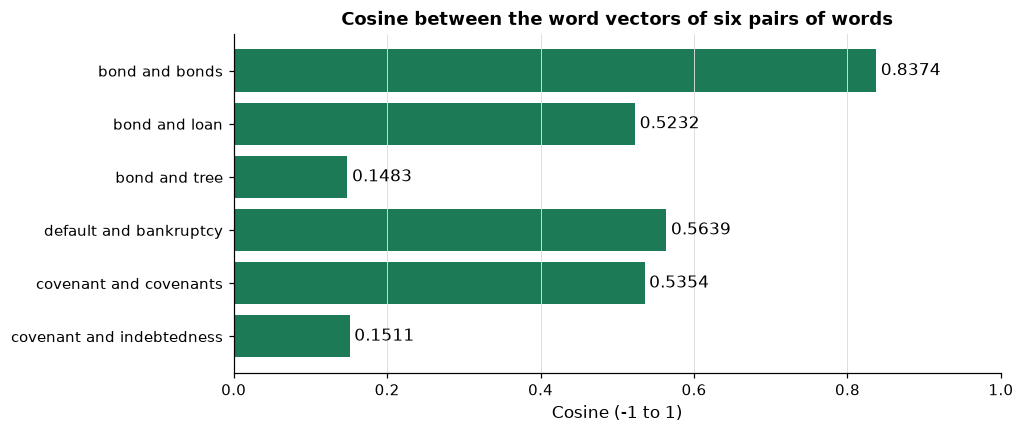

,cosine
bond and bonds,0.8374
bond and loan,0.5232
bond and tree,0.1483
default and bankruptcy,0.5639
covenant and covenants,0.5354
covenant and indebtedness,0.1511


In [12]:
pairs = [("bond", "bonds"), ("bond", "loan"), ("bond", "tree"), ("default", "bankruptcy"),
         ("covenant", "covenants"), ("covenant", "indebtedness")]
for a, b in pairs:
    # one row against one row: the result is a 1 x 1 table, so [0, 0] takes its only number
    cosine = textkit.cosine_similarity_matrix(vectors[[position[a]]], vectors[[position[b]]])[0, 0]
    print(f"{a:>9} and {b:<13} cosine {cosine:.4f}")
# the same six cosines as bars and as a table
pair_cosines = pd.Series(
    {f"{a} and {b}": textkit.cosine_similarity_matrix(vectors[[position[a]]], vectors[[position[b]]])[0, 0] for a, b in pairs},
    name="cosine")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(pair_cosines.index[::-1], pair_cosines.to_numpy()[::-1], color=plotkit.GREEN)
ax.bar_label(ax.containers[0], fmt="%.4f", padding=3)
ax.set_title("Cosine between the word vectors of six pairs of words")
ax.set_xlabel("Cosine (-1 to 1)")
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
plt.show()
plotkit.styled(pair_cosines.to_frame(), ["cosine"], "Cosine of six pairs of words, GloVe's 100-number vectors", fmt="{:.4f}")

* The longest bar is "bond" with "bonds", 0.8374; "bond" with "tree" is the shortest, 0.1483. Excel draws these as a bar chart.
* "bond" and "bonds" have a cosine of 0.8374; "bond" and "loan" 0.5232; "bond" and "tree" 0.1483. In TF-IDF every one of these pairs would be two separate columns with nothing in common.
* "covenant" and "indebtedness", two words that sit side by side in every indenture, have a cosine of only 0.1511. The vectors come from general English text, not from indentures.

Q. Add `nearest_words` to `textkit.py`, and its three tests.

In [13]:
%%writefile -a textkit.py


def nearest_words(vectors, words: list[str], word: str, k: int = 5) -> pd.Series:
    """The k words whose vectors have the largest cosine with one word's vector.

    Inputs: vectors and words, as load_word_vectors returns them; word, the word to start from (looked up as
    given, so lower-case it for GloVe); k, how many neighbours.
    Output: a Series indexed by word, holding the cosine (-1 to 1), largest first, the word itself left out, ties
    broken by the word alphabetically.
    Convention: a near neighbour is a word used in similar contexts in the training text, not a synonym and not a
    meaning.
    Raises KeyError naming the word if it is not in the list, and ValueError if k is below 1.
    """
    if k < 1:
        raise ValueError("k must be at least 1")
    try:
        position = words.index(word)
    except ValueError:
        raise KeyError(f"{word!r} is not in the word list") from None
    similarity = cosine_similarity_matrix(vectors, np.asarray(vectors)[[position]])[:, 0]
    table = pd.DataFrame({"word": words, "cosine": similarity}).drop(index=position)
    table = table.sort_values(["cosine", "word"], ascending=[False, True], kind="mergesort").head(k)
    return pd.Series(table["cosine"].to_numpy(), index=pd.Index(table["word"], name="word"), name=word)

Appending to textkit.py


In [14]:
%%writefile -a test_textkit.py


def small_vectors() -> tuple[np.ndarray, list[str]]:
    """A five-word table typed for the tests: two pairs of near words and one word on its own."""
    words = ["bond", "bonds", "loan", "loans", "tree"]
    vectors = np.array([[1.0, 0.0, 0.0], [0.9, 0.1, 0.0], [0.0, 1.0, 0.0], [0.1, 0.9, 0.0], [0.0, 0.0, 1.0]],
                       dtype=np.float32)
    return vectors, words


def test_nearest_words_excludes_itself():
    vectors, words = small_vectors()
    near = textkit.nearest_words(vectors, words, "bond", k=2)
    assert "bond" not in near.index
    assert near.index[0] == "bonds"


def test_nearest_words_ties_by_word():
    vectors, words = small_vectors()
    # "tree" is at cosine 0 from every other word: the ties come out in alphabetical order
    near = textkit.nearest_words(vectors, words, "tree", k=4)
    assert list(near.index) == ["bond", "bonds", "loan", "loans"]


def test_nearest_words_unknown_raises():
    vectors, words = small_vectors()
    with pytest.raises(KeyError, match="covenant"):
        textkit.nearest_words(vectors, words, "covenant")

Appending to test_textkit.py


* `nearest_words` computes the cosine of one word's vector with every row at once (one matrix product), drops the word itself, and sorts by cosine, largest first. Ties are broken by the word, alphabetically, so the order never depends on how numpy happens to sort equal numbers.
* A word that is not in the list raises a `KeyError` that names it, rather than returning something.
* The tests use `small_vectors`, a five-word table typed by hand: "bond" and "bonds" point almost the same way, "loan" and "loans" another way, and "tree" a third way, at cosine 0 from all of them, so the ties test has four equal cosines to sort.

Q. Reload and run the tests.

In [15]:
importlib.reload(textkit)
print(f"nearest_words in textkit: {hasattr(textkit, 'nearest_words')}")

nearest_words in textkit: True


In [16]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_textkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.......................                                                  [100%]
23 passed in 1.99s



* `23 passed`.

Q. Which five words are nearest to "bond", "default", "inflation", and "covenant"? Print them, draw them as bars, then draw all 24 vectors in two dimensions.

     bond: bonds 0.8374, treasury 0.7194, benchmark 0.6848, interest 0.6838, 30-year 0.6831
  default: debt 0.6499, borrower 0.6422, borrowers 0.6409, issuer 0.6320, defaults 0.6314
inflation: rate 0.7825, rates 0.7814, unemployment 0.7501, inflationary 0.7441, growth 0.7436
 covenant: lutheran 0.5579, charter 0.5547, covenants 0.5354, enshrined 0.5040, principles 0.5027


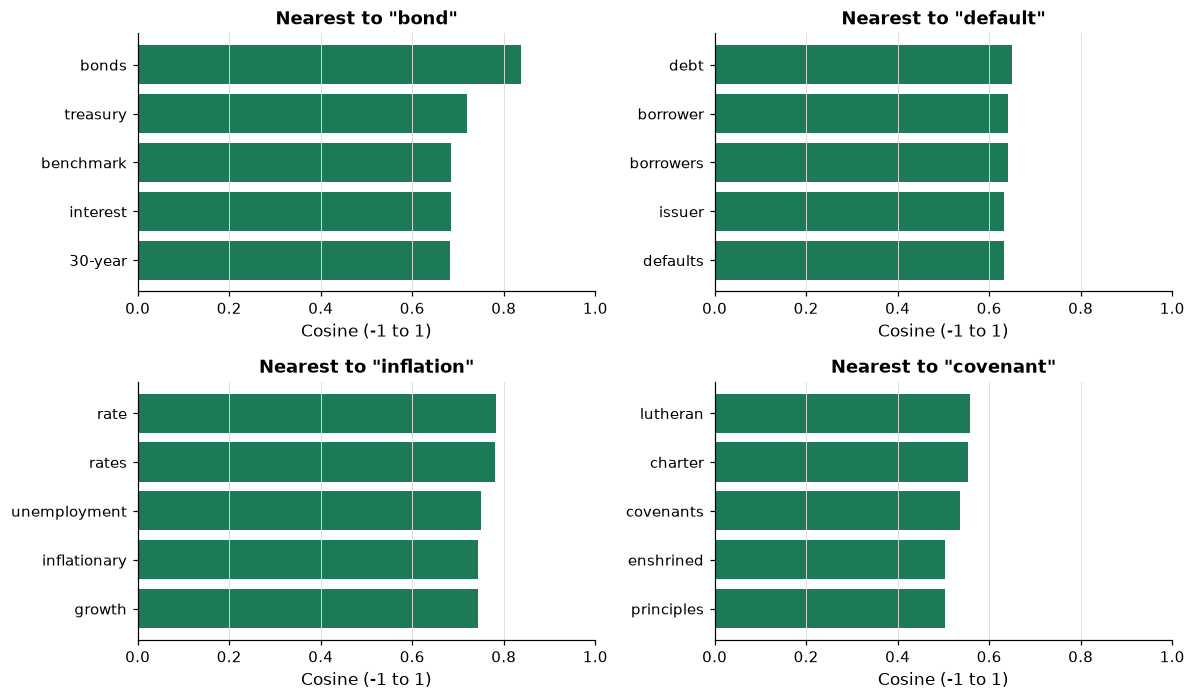

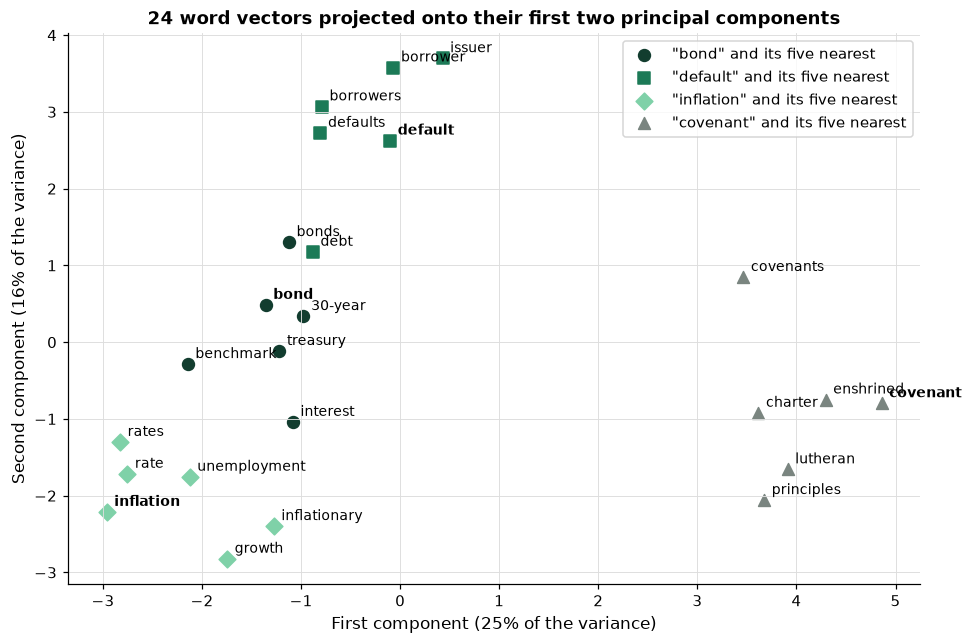

In [17]:
nearest = {word: textkit.nearest_words(vectors, words, word, k=5) for word in ["bond", "default", "inflation", "covenant"]}
for word, near in nearest.items():
    print(f"{word:>9}: " + ", ".join(f"{w} {c:.4f}" for w, c in near.items()))
# the five nearest words of each query word, as four panels of bars
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for ax, (word, near) in zip(axes.ravel(), nearest.items()):
    ax.barh(near.index[::-1], near.to_numpy()[::-1], color=plotkit.GREEN)
    ax.set_title(f'Nearest to "{word}"')
    ax.set_xlabel("Cosine (-1 to 1)")
    ax.set_xlim(0, 1)
    ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

from sklearn.decomposition import PCA

# demonstration: the four query words and their five nearest words: 24 vectors of 100 numbers, projected onto their first two
# principal components (PCA finds the two directions along which the 24 vectors differ most)
groups = {word: [word] + list(near.index) for word, near in nearest.items()}
group_words = [w for group in groups.values() for w in group]
pca = PCA(n_components=2, random_state=SEED).fit(vectors[[position[w] for w in group_words]].astype(np.float64))
fig, ax = plt.subplots(figsize=(10, 6.5))
for (word, group), colour, marker in zip(groups.items(), [plotkit.GREEN_DARK, plotkit.GREEN, plotkit.GREEN_LIGHT, plotkit.GREY], "osD^"):
    points = pca.transform(vectors[[position[w] for w in group]].astype(np.float64))
    ax.scatter(points[:, 0], points[:, 1], s=60, color=colour, marker=marker, label=f'"{word}" and its five nearest')
    for w, (x, y) in zip(group, points):
        # the query word in bold, its neighbours in plain text
        ax.annotate(w, (x, y), xytext=(5, 4), textcoords="offset points", fontsize=9,
                    fontweight="bold" if w == word else "normal")
ax.set_title("24 word vectors projected onto their first two principal components")
ax.set_xlabel(f"First component ({pca.explained_variance_ratio_[0]:.0%} of the variance)")
ax.set_ylabel(f"Second component ({pca.explained_variance_ratio_[1]:.0%} of the variance)")
ax.legend(loc="best")
plt.show()

* The bars for "bond" run from 0.68 to 0.84, those for "covenant" only from 0.50 to 0.56: a word whose neighbours in general English sit further away has shorter bars. The projection keeps 41% of the variance of the 24 vectors (25% on the first component, 16% on the second), so distances on it are a rough picture. The "covenant" words sit alone on the right; along the vertical axis the "default" words are the highest and the "inflation" words the lowest, with the "bond" words between.
* "bond" sits nearest to "bonds", "treasury", "benchmark", "interest", "30-year": the vectors place it among the words of the bond market. "default" sits beside "debt", "borrower", "borrowers", "issuer", the credit sense of the word.
* "covenant" does not: its nearest word is "lutheran", then "charter", "covenants", "enshrined", "principles". Its neighbours are words of churches and of founding documents, and its own plural comes third: the vectors record the company the word keeps in their training text, and there that company is not an indenture's.
* That is the lesson of the day in one line. A nearest word is a word used in similar contexts **in the training text**, here general English; it is not a synonym, and it is not what the word means in an indenture.

## 4.3 What Is Missing

A word with no row has no vector. Before using the vectors on an indenture, count what they do not cover.

Q. Add `document_vectors` to `textkit.py`, and its two tests. It averages the vectors of a text's tokens and reports the share of tokens it could not find.

In [18]:
%%writefile -a textkit.py


def document_vectors(texts: list[str], vectors, words: list[str]) -> tuple[np.ndarray, np.ndarray]:
    """The mean word vector of each text, and each text's share of tokens not in the word list.

    Inputs: texts; vectors and words, as load_word_vectors returns them.
    Output: (matrix, missing_share): a float64 array, one row per text (the mean of the vectors of its tokens found
    in the list), and a float64 array of the share of each text's tokens not found (0 to 1). A text with no token
    found gets a row of zeros and share 1.0, so an empty text never becomes NaN.
    Convention: tokens come from tokenize, lower case, because GloVe is uncased; a token is counted once each time
    it appears. Averaging keeps no word order and gives every token the same weight.
    Raises ValueError if texts is empty.
    """
    if len(texts) == 0:
        raise ValueError("texts is empty")
    vectors = np.asarray(vectors)
    position = {w: i for i, w in enumerate(words)}
    matrix = np.zeros((len(texts), vectors.shape[1]), dtype=np.float64)
    missing = np.ones(len(texts), dtype=np.float64)
    for row, text in enumerate(texts):
        tokens = tokenize(text)
        found = [position[t] for t in tokens if t in position]
        if found:
            matrix[row] = vectors[found].astype(np.float64).mean(axis=0)
            missing[row] = 1.0 - len(found) / len(tokens)
    return matrix, missing

Appending to textkit.py


In [19]:
%%writefile -a test_textkit.py


def test_document_vectors_missing_share():
    vectors, words = small_vectors()
    # capitals are lower-cased first: "Bonds" and "Loan" are found, "Indenture" and "and" are not
    matrix, missing = textkit.document_vectors(["Bonds and Loan Indenture"], vectors, words)
    assert missing[0] == 0.5
    assert np.allclose(matrix[0], (vectors[1] + vectors[2]) / 2, atol=1e-7)


def test_document_vectors_empty_text_zero():
    vectors, words = small_vectors()
    matrix, missing = textkit.document_vectors(["", "covenant"], vectors, words)
    assert (matrix == 0).all() and list(missing) == [1.0, 1.0]

Appending to test_textkit.py


* Each text is cut into tokens by `tokenize`, lower case, because GloVe is uncased. Each token found in the list contributes its vector; the row is their mean. A token counts every time it appears.
* `missing` starts at 1.0 for every text and becomes the share of tokens not found. A text with no token found keeps a row of zeros and a share of 1.0, so an empty text never becomes `NaN` (not a number).
* The first test plants capitals ("Bonds", "Loan", "Indenture") on purpose: lower-cased, "bonds" and "loan" are found and "and" and "indenture" are not, a share of 0.5.

Q. Reload and run all of today's tests.

In [20]:
importlib.reload(textkit)
print(f"document_vectors in textkit: {hasattr(textkit, 'document_vectors')}")

document_vectors in textkit: True


In [21]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_textkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.........................                                                [100%]
25 passed in 2.00s



* `25 passed`: day 3's 20 and today's five.

Q. Which tokens of the Boyd indenture have no vector, and how many are there?

tokens: 63,810; with no vector: 422 (137 distinct)


document_vectors' missing share for the whole indenture: 0.0066
         token  count
     company's     55
    defeasance     44
    incurrence     27
      holder's     12
       owner's     12
         4.750     10
     trustee's      9
       moody's      8
      defeased      7
non-appealable      6
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495.


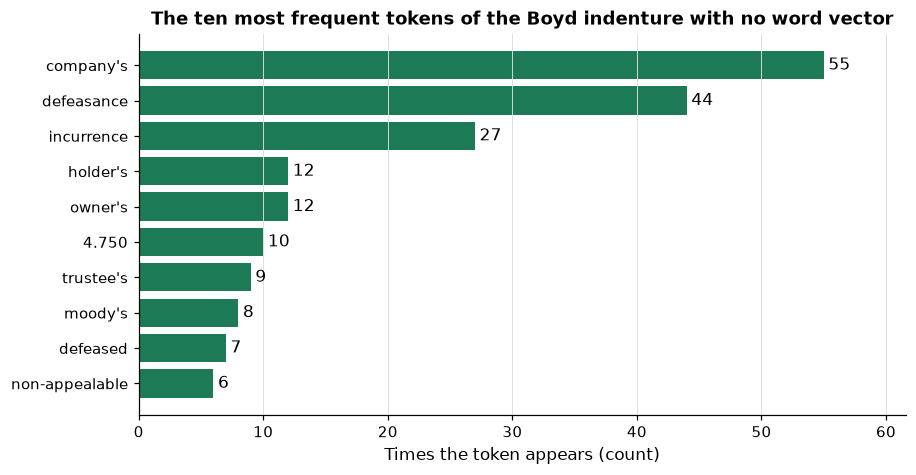

In [22]:
# source text: quoted as published
import collections

# the course's source line for this indenture, and a section when one is shown
BOYD = ("Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed "
        "2021-06-08, accession 0001193125-21-185495")


def boyd_source(section=None):
    """The source line for an excerpt of the Boyd indenture."""
    return f"Source: {BOYD}" + (f", Section {section}." if section else ".")


indenture = Path("course7_indentures/boyd_2021.txt").read_text(encoding="utf-8")
tokens = textkit.tokenize(indenture)
# the tokens with no row in the word list, counted
missing = collections.Counter(t for t in tokens if t not in position)
print(f"tokens: {len(tokens):,}; with no vector: {sum(missing.values()):,} ({len(missing)} distinct)")
matrix, share = textkit.document_vectors([indenture], vectors, words)
print(f"document_vectors' missing share for the whole indenture: {share[0]:.4f}")
# the ten most frequent tokens with no vector (the indenture's own words, cut at ten)
print(pd.DataFrame(missing.most_common(10), columns=["token", "count"]).to_string(index=False))
print(boyd_source())
# the ten most frequent missing tokens as bars
top_missing = missing.most_common(10)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh([t for t, _ in top_missing][::-1], [n for _, n in top_missing][::-1], color=plotkit.GREEN)
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("The ten most frequent tokens of the Boyd indenture with no word vector")
ax.set_xlabel("Times the token appears (count)")
ax.set_xlim(0, top_missing[0][1] * 1.12)
ax.grid(axis="y", visible=False)
plt.show()

* The bars are the indenture's own words and its possessives: "company's" leads with 55, ahead of "defeasance" at 44.
* 422 of 63,810 tokens have no vector, a share of 0.0066, from 137 distinct tokens. The share is small partly by the course's design: the subset keeps every token of the course's texts that GloVe has, so a token is missing only when GloVe itself lacks it.
* The most frequent missing token is "company's" (55 times). GloVe's vocabulary holds "'s" as a token of its own (row 9) and no "company's", while `tokenize` keeps "company's" whole, so every possessive (132 tokens ending in "'s" in all) misses. The others are the indenture's own vocabulary: "defeasance", "incurrence". A tokenizer and a vector table must agree on what a token is.

Q. Which of the 136 defined terms of Section 1.01 hold a token with no vector?

In [23]:
# source text: quoted as published
sections = textkit.find_sections(indenture).set_index("number")
section_101 = indenture[sections.loc["1.01", "start"]:sections.loc["1.01", "end"]]
terms = textkit.defined_terms(section_101)
for term in terms["term"]:
    lost = [t for t in textkit.tokenize(term) if t not in position]
    if lost:
        print(f"{term}: {lost}")
print(boyd_source("1.01"))

Defeased Indebtedness: ['defeased']
Moody's: ["moody's"]
QIB: ['qib']
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 1.01.


* Only 3 of 136: "Defeased Indebtedness", "Moody's", and "QIB". Almost every defined term is made of ordinary English words that GloVe has.
* That is the deeper problem: the words are found, and the **definitions** are not. GloVe has one vector for "indebtedness", learned from news and encyclopedia text, and it knows nothing of the clauses that Section 1.01 gives "Indebtedness".

Q. What does lower case lose in Section 4.12? Count its capitalised tokens, and look at the nearest words of three of them.

tokens in Section 4.12: 1,840; capitalised: 374
most frequent capitalised: [('Indebtedness', 67), ('Company', 33), ('Restricted', 24), ('Subsidiary', 21), ('Incurred', 14)]
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 4.12.
       notes: note, letters, write, written, books
indebtedness: repayments, borrowings, debts, liabilities, arrears


        lien: soong, siew, hsieh, chen, kmt


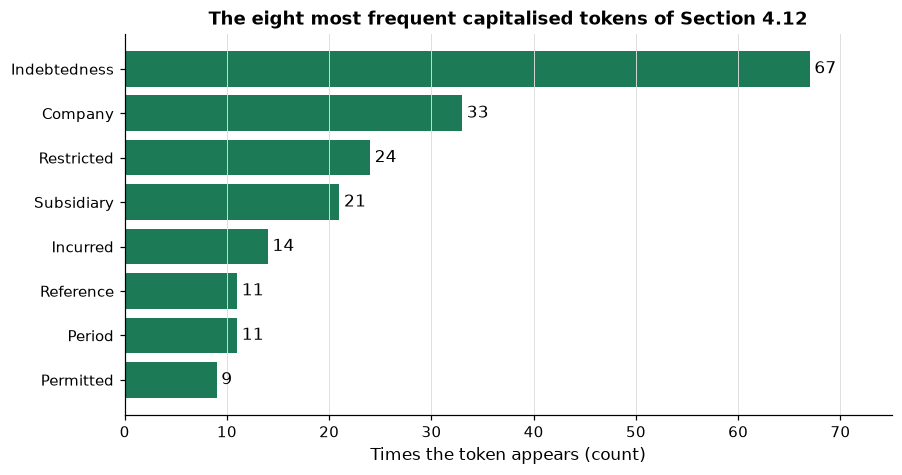

In [24]:
# source text: quoted as published
section_412 = indenture[sections.loc["4.12", "start"]:sections.loc["4.12", "end"]]
# tokenize with lower=False keeps capitals, so the defined terms show
capitalised = collections.Counter(t for t in textkit.tokenize(section_412, lower=False) if t != t.lower())
print(f"tokens in Section 4.12: {len(textkit.tokenize(section_412)):,}; capitalised: {sum(capitalised.values())}")
print(f"most frequent capitalised: {capitalised.most_common(5)}")
print(boyd_source("4.12"))
for word in ["notes", "indebtedness", "lien"]:
    near = textkit.nearest_words(vectors, words, word, k=5)
    print(f"{word:>12}: {', '.join(near.index)}")
# the eight most frequent capitalised tokens of Section 4.12
top_caps = capitalised.most_common(8)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh([t for t, _ in top_caps][::-1], [n for _, n in top_caps][::-1], color=plotkit.GREEN)
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("The eight most frequent capitalised tokens of Section 4.12")
ax.set_xlabel("Times the token appears (count)")
ax.set_xlim(0, top_caps[0][1] * 1.12)
ax.grid(axis="y", visible=False)
plt.show()

* The longest bar, "Indebtedness" at 67, is a defined term; lower-cased for GloVe it becomes the ordinary word.
* 374 of the 1,840 tokens of Section 4.12 are capitalised, most of them defined terms: "Indebtedness" alone 67 times. Lower-cased for GloVe, each becomes the ordinary word.
* "notes" is nearest to "note", "letters", "write": the Notes of an indenture are debt securities, and the vectors return notes you write. "lien" is nearest to "soong", "siew", "hsieh": words that have nothing to do with a security interest: in news text "lien" also occurs as a name. "indebtedness" stays close to its sense ("repayments", "borrowings", "debts").
* Uncased vectors cannot tell a defined term from the ordinary word. Day 6's sentence embeddings take whole sentences, so the words around a word count too.

## 4.4 Arithmetic on Vectors, Once

**How it works.** If a direction in the table stands for a relation, say singular to plural, then adding the difference of one pair to a third word should land near that word's partner. `analogy` computes the vector of b minus a plus c, finds the rows with the largest cosine to it, and leaves the three input words out. You control the three words and how many neighbours to return. What comes out is a list of nearest words, always, whether or not the relation holds; section 4.7 draws how rough the direction is.

Word vectors became famous for one trick: subtract one word's vector from another's, add a third, and look for the nearest word to the result. The GloVe page names what it shows "linear substructures". It is shown here once, with a caution after it.

Q. Write `analogy(a, b, c)`: the vector of b minus a plus c, and its nearest words, leaving out the three words given.

bonds - bond + loan:     loans 0.8071, debt 0.6993, repay 0.6697


paris - france + germany: berlin 0.8810, frankfurt 0.7958, vienna 0.7605
king - man + woman:      queen 0.7834, monarch 0.6934, throne 0.6833


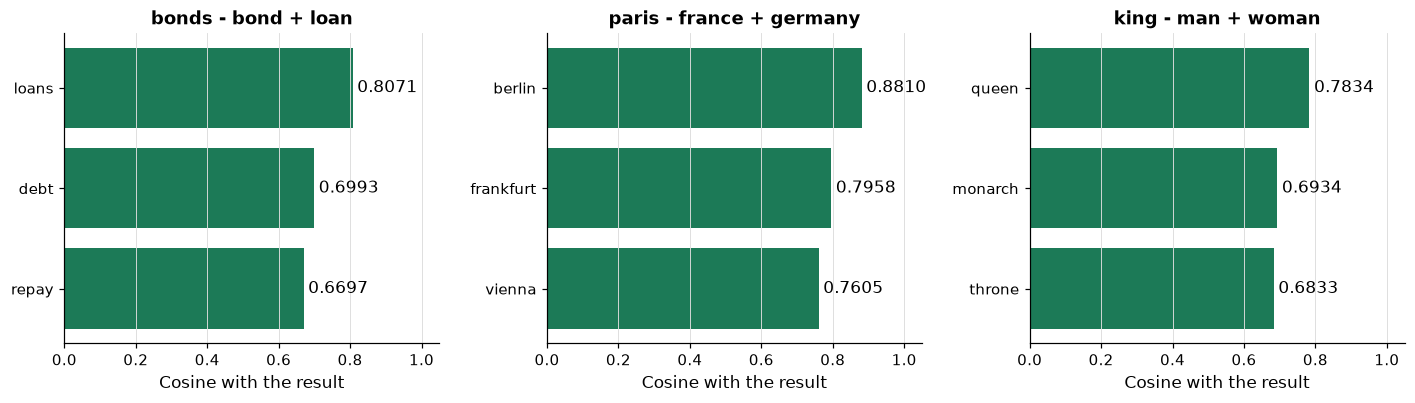

In [25]:
def analogy(a, b, c, k=3):
    """The k words nearest to vector(b) - vector(a) + vector(c), the three input words left out."""
    query = (vectors[position[b]].astype(np.float64) - vectors[position[a]] + vectors[position[c]])[None, :]
    cosine = textkit.cosine_similarity_matrix(vectors, query)[:, 0]
    table = pd.DataFrame({"word": words, "cosine": cosine})
    table = table[~table["word"].isin([a, b, c])]
    # largest cosine first, ties by the word
    table = table.sort_values(["cosine", "word"], ascending=[False, True], kind="mergesort").head(k)
    return ", ".join(f"{w} {s:.4f}" for w, s in zip(table["word"], table["cosine"]))


print(f"bonds - bond + loan:     {analogy('bond', 'bonds', 'loan')}")
print(f"paris - france + germany: {analogy('france', 'paris', 'germany')}")
print(f"king - man + woman:      {analogy('man', 'king', 'woman')}")
# the three nearest words of each result as bars, read back from the same text
queries = [("bond", "bonds", "loan"), ("france", "paris", "germany"), ("man", "king", "woman")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, query in zip(axes, queries):
    top = [(part.rsplit(" ", 1)[0], float(part.rsplit(" ", 1)[1])) for part in analogy(*query).split(", ")]
    ax.barh([w for w, _ in top][::-1], [c for _, c in top][::-1], color=plotkit.GREEN)
    ax.bar_label(ax.containers[0], fmt="%.4f", padding=3)
    ax.set_title(f"{query[1]} - {query[0]} + {query[2]}")
    ax.set_xlabel("Cosine with the result")
    ax.set_xlim(0, 1.05)
    ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

* In each panel the first bar is the answer and the other two are words that keep similar company; the cosines run from 0.67 to 0.88.
* The plural of "loan" comes out as "loans", the capital of Germany as "berlin", and the textbook example gives "queen".
* **The caution.** The arithmetic finds the nearest row to a point; it always returns some word, right or wrong, and leaving out the three input words is part of the method. A nearest word is not a meaning and not a fact. The course uses the vectors as features in the next section and never reads an answer off them.

## 4.5 Document Vectors as Features

**How it works.** A classifier needs one row of numbers per section, and a section has many words. `document_vectors` looks up the vector of each token, skips the tokens with none, and takes the mean of the rest, so every section becomes one list of 100 numbers whatever its length. A logistic regression is then fitted on those lists, as on day 3 it was fitted on TF-IDF rows. You control the vectors, which tokens count, and the classifier. What comes out is a table with one row per section, and the share of the section's tokens that had no vector.

Day 3 classified the 8-K sections by their item with TF-IDF and a logistic regression. Here each section becomes **one** vector of 100 numbers, the mean of its words' GloVe vectors, and the same kind of logistic regression is fitted on those vectors. Both models use the same rows: fitted on the sections filed from 2019 to 2023, scored on the sections filed in 2024. The 2025 sections stay closed until day 10.

Q. Load the 8-K sections and split them by date, as day 3 did.

In [26]:
eightk = pd.read_csv("course7_8k_items.csv", dtype={"item": str})
# training to 2023-12-31, validation in 2024; the 2025 rows are kept aside, closed, and never scored here
train, valid, closed = textkit.date_split(eightk, "filed", "2023-12-31", "2024-12-31")
print(f"training sections (2019 to 2023): {len(train):,}; validation sections (2024): {len(valid)}; "
      f"closed until day 10 (2025): {len(closed)}")
items = list(textkit.ITEM_TITLES)
print(f"items: {items}")

training sections (2019 to 2023): 3,650; validation sections (2024): 741; closed until day 10 (2025): 735
items: ['1.01', '1.03', '2.02', '2.03', '2.04', '2.06', '3.01', '5.02']


Q. Turn every training and validation section into its mean word vector. How much of the text has no vector?

training: 3,650 rows of 100 numbers; validation: 741 rows
mean missing share: training 0.0186, validation 0.0188; largest in validation 0.0971


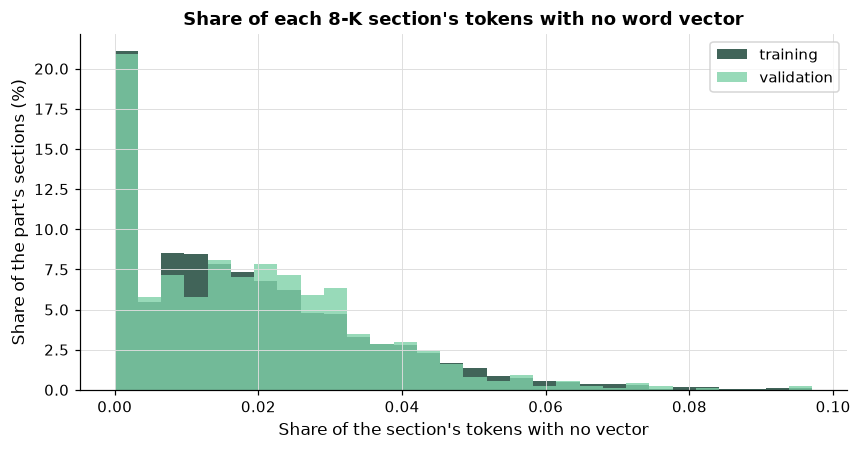

In [27]:
X_train, missing_train = textkit.document_vectors(train["text"].tolist(), vectors, words)
X_valid, missing_valid = textkit.document_vectors(valid["text"].tolist(), vectors, words)
print(f"training: {X_train.shape[0]:,} rows of {X_train.shape[1]} numbers; validation: {X_valid.shape[0]} rows")
print(f"mean missing share: training {missing_train.mean():.4f}, validation {missing_valid.mean():.4f}; "
      f"largest in validation {missing_valid.max():.4f}")
# how the share is spread over the sections of each part, as histograms in percent of the part's sections
edges = np.linspace(0, missing_valid.max(), 31)
fig, ax = plt.subplots(figsize=(9, 4.2))
for part, shares, colour in (("training", missing_train, plotkit.GREEN_DARK), ("validation", missing_valid, plotkit.GREEN_LIGHT)):
    ax.hist(shares, bins=edges, weights=np.full(len(shares), 100 / len(shares)), color=colour, alpha=0.8, label=part)
ax.set_title("Share of each 8-K section's tokens with no word vector")
ax.set_xlabel("Share of the section's tokens with no vector")
ax.set_ylabel("Share of the part's sections (%)")
ax.legend()
plt.show()

* Most of the mass sits at the left in both parts: the median section misses 0.0167 of its tokens, and the training and validation histograms have the same shape.
* Each section of up to 300 words is now 100 numbers. On average 0.0188 of a validation section's tokens have no vector, 0.0971 at most.

Q. Fit a logistic regression on the training vectors, and report precision, recall, and F1 per item on validation.

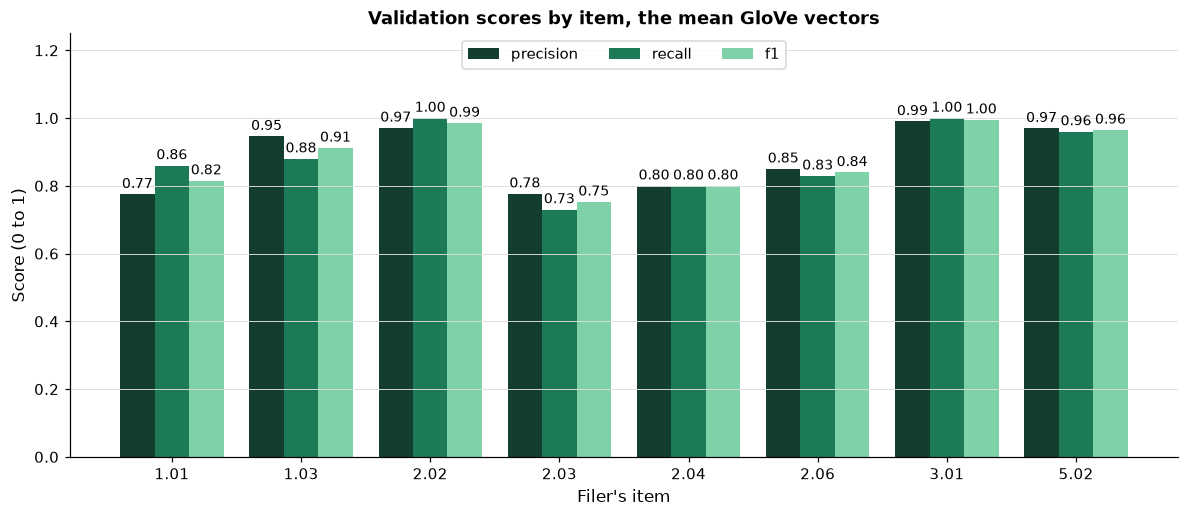

,precision,recall,f1,support
label,,,,
1.01,0.7748,0.8600,0.8152,100
1.03,0.9462,0.8800,0.9119,100
2.02,0.9709,1.0000,0.9852,100
2.03,0.7766,0.7300,0.7526,100
2.04,0.8000,0.8000,0.8000,100
2.06,0.8500,0.8293,0.8395,41
3.01,0.9901,1.0000,0.9950,100
5.02,0.9697,0.9600,0.9648,100
macro,0.8848,0.8824,0.8830,741


In [28]:
from sklearn.linear_model import LogisticRegression

# the same classifier as day 3's second step, on 100 numbers per section instead of TF-IDF columns;
# tol=1e-10 fits it to its optimum (see below the output)
glove_model = LogisticRegression(max_iter=10_000, tol=1e-10, random_state=SEED).fit(X_train, train["item"])
report_glove = textkit.item_report(valid["item"], glove_model.predict(X_valid), items)
# one group of bars per item: precision, recall, and F1 on the validation sections
fig, ax = plt.subplots(figsize=(13, 5))
plotkit.bars(report_glove.drop(index="macro")[["precision", "recall", "f1"]], "Validation scores by item, the mean GloVe vectors",
             "Score (0 to 1)", ax=ax, fmt="{:.2f}")
ax.set_xlabel("Filer's item")
ax.set_ylim(0, 1.25)
ax.legend(ncol=3, loc="upper center")
plt.show()
plotkit.styled(report_glove, [], f"Validation scores by item and the macro mean, a logistic regression on the mean GloVe vectors, "
               f"scored on the {len(valid)} validation sections", fmt="{:.4f}")

* The lowest group of bars is Item 2.03, F1 0.7526; Item 3.01 and Item 2.02 stay highest.
* Macro F1 on validation: 0.8830. **Rows.** Every model on the 8-K sections in this notebook is fitted on the 3,650 sections filed from 2019 to 2023 and scored on the 741 sections filed in 2024, labelled validation; the 735 sections filed in 2025 are closed until day 10.
* **Why `tol=1e-10`.** At scikit-learn's default tolerance (`tol=1e-4`, `max_iter=2000` in day 3's pipeline) the solver stopped on these vectors before it reached the optimum, and where it stopped depended on the last digits of its arithmetic: the course's build ran it on one thread and on all threads and got different F1s on Items 1.01 and 2.03. A logistic regression with its default penalty has one optimum, so a much smaller tolerance takes both runs there, and they agree. The tolerance is a setting of the solver, not of the model.
* Nothing needs to sit inside a `Pipeline` here: the vectors were learned by the GloVe authors on their own text, and `document_vectors` learns nothing from the 8-K rows, so no training row's information can reach the validation rows through it.

Q. Fit day 3's TF-IDF model on the same training rows and put the two side by side, with the majority item as the baseline for accuracy.

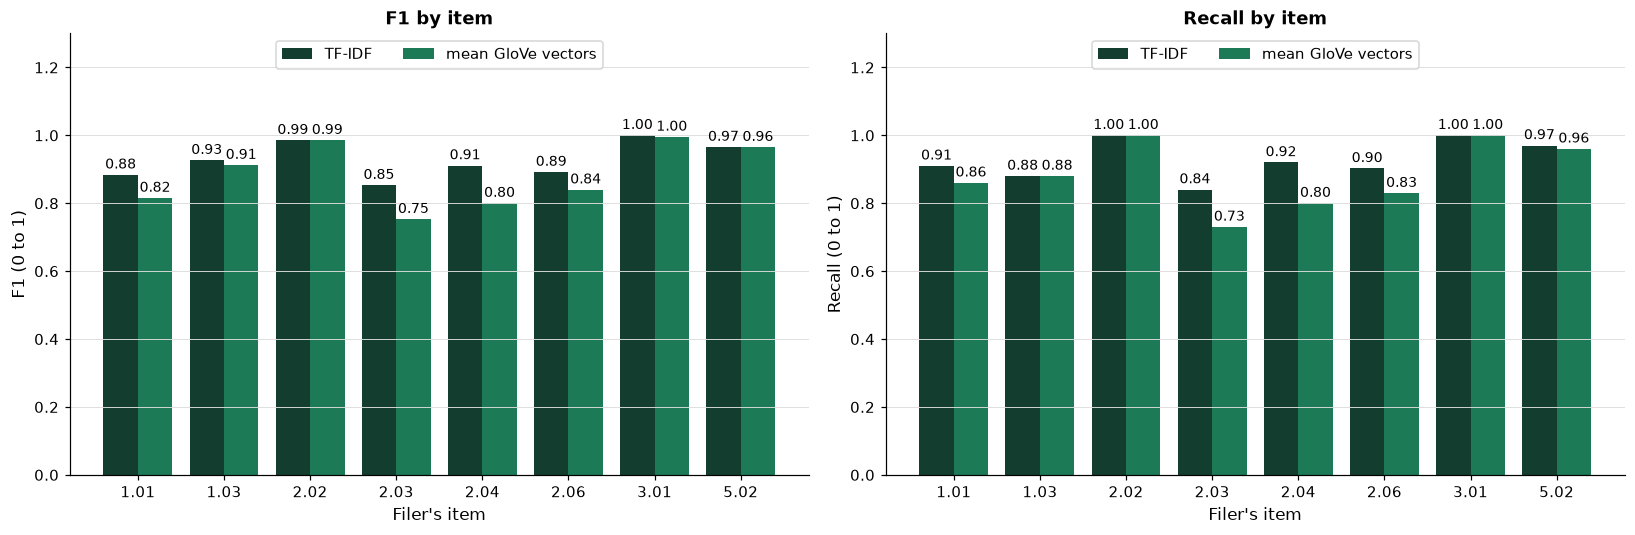

,TF-IDF f1,GloVe mean f1,TF-IDF recall,GloVe mean recall
label,,,,
1.01,0.8835,0.8152,0.9100,0.8600
1.03,0.9263,0.9119,0.8800,0.8800
2.02,0.9852,0.9852,1.0000,1.0000
2.03,0.8528,0.7526,0.8400,0.7300
2.04,0.9109,0.8000,0.9200,0.8000
2.06,0.8916,0.8395,0.9024,0.8293
3.01,1.0000,0.9950,1.0000,1.0000
5.02,0.9652,0.9648,0.9700,0.9600
macro,0.9269,0.8830,0.9278,0.8824


items tied at the largest training count (500): 5; majority item 1.01
accuracy on validation: majority item 0.1350, TF-IDF 0.9298, GloVe mean 0.8866


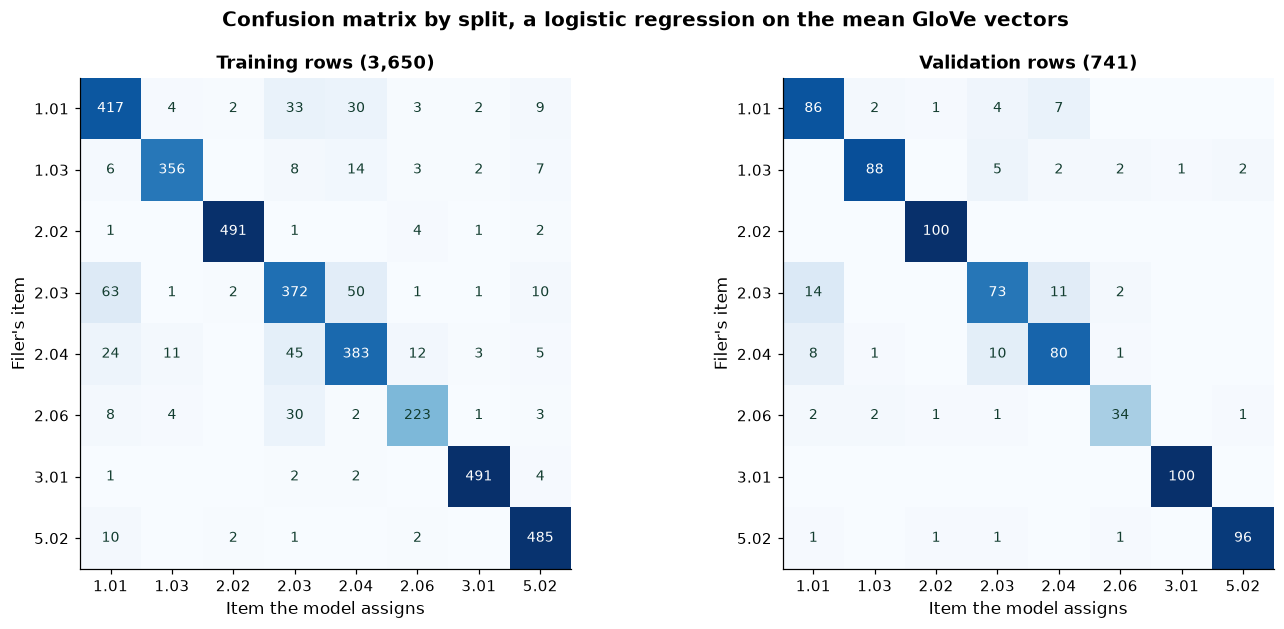

,sections,off the diagonal,macro F1,accuracy
rows,,,,
training,"3,650",432,0.8810,0.8816
validation,741,84,0.8830,0.8866


In [29]:
tfidf_model = textkit.text_classifier().fit(train["text"], train["item"])
report_tfidf = textkit.item_report(valid["item"], tfidf_model.predict(valid["text"]), items)
side = pd.DataFrame({"TF-IDF f1": report_tfidf["f1"], "GloVe mean f1": report_glove["f1"],
                     "TF-IDF recall": report_tfidf["recall"], "GloVe mean recall": report_glove["recall"]})
# F1 and recall by item for the two models, as paired bars, and the same numbers as a table
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 5))
plotkit.bars(side.drop(index="macro")[["TF-IDF f1", "GloVe mean f1"]].rename(columns={"TF-IDF f1": "TF-IDF", "GloVe mean f1": "mean GloVe vectors"}),
             "F1 by item", "F1 (0 to 1)", ax=left, fmt="{:.2f}")
plotkit.bars(side.drop(index="macro")[["TF-IDF recall", "GloVe mean recall"]].rename(columns={"TF-IDF recall": "TF-IDF", "GloVe mean recall": "mean GloVe vectors"}),
             "Recall by item", "Recall (0 to 1)", ax=right, fmt="{:.2f}")
for ax in (left, right):
    ax.set_xlabel("Filer's item")
    ax.set_ylim(0, 1.3)
    ax.legend(ncol=2, loc="upper center")
fig.tight_layout()
plt.show()
# the cell goes on, so the table is shown with display()
display(plotkit.styled(side, [], f"F1 and recall by item for the TF-IDF model and the mean GloVe vectors, scored on the {len(valid)} validation sections",
                       fmt="{:.4f}"))

# the majority item of the training rows, ties broken by the item code, as the baseline for accuracy
counts = train["item"].value_counts()
majority = sorted(counts.index, key=lambda item: (-counts[item], item))[0]
print(f"items tied at the largest training count ({counts.max()}): {(counts == counts.max()).sum()}; majority item {majority}")
print(f"accuracy on validation: majority item {(valid['item'] == majority).mean():.4f}, "
      f"TF-IDF {(tfidf_model.predict(valid['text']) == valid['item']).mean():.4f}, "
      f"GloVe mean {(glove_model.predict(X_valid) == valid['item']).mean():.4f}")

# the mean-vector model's confusion matrices: training, then validation (the test rows stay closed until day 10)
glove_train_assigned = glove_model.predict(X_train)
glove_valid_assigned = glove_model.predict(X_valid)


def item_heatmap(ax, truth, assigned, title):
    """One 8 by 8 confusion matrix as a heatmap: the count in each cell, an empty cell left blank."""
    values = pd.crosstab(truth, assigned).reindex(index=items, columns=items, fill_value=0).to_numpy()
    ax.imshow(values, cmap="Blues", vmin=0, vmax=values.max())
    ax.grid(False)
    for row in range(len(items)):
        for col in range(len(items)):
            if values[row, col]:
                # dark cells get white text, light cells dark text
                ax.text(col, row, f"{values[row, col]:,}", ha="center", va="center", fontsize=9,
                        color="white" if values[row, col] > values.max() / 2 else plotkit.GREEN_DARK)
    ax.set_xticks(range(len(items)), labels=items)
    ax.set_yticks(range(len(items)), labels=items)
    ax.set_xlabel("Item the model assigns")
    ax.set_ylabel("Filer's item")
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
item_heatmap(axes[0], train["item"], glove_train_assigned, f"Training rows ({len(train):,})")
item_heatmap(axes[1], valid["item"], glove_valid_assigned, f"Validation rows ({len(valid):,})")
fig.suptitle("Confusion matrix by split, a logistic regression on the mean GloVe vectors", fontweight="bold")
fig.tight_layout()
plt.show()
train_report_glove = textkit.item_report(train["item"], glove_train_assigned, items)
by_split = pd.DataFrame(
    {"sections": [len(train), len(valid)],
     "off the diagonal": [(glove_train_assigned != train["item"].to_numpy()).sum(), (glove_valid_assigned != valid["item"].to_numpy()).sum()],
     "macro F1": [train_report_glove.loc["macro", "f1"], report_glove.loc["macro", "f1"]],
     "accuracy": [(glove_train_assigned == train["item"].to_numpy()).mean(), (glove_valid_assigned == valid["item"].to_numpy()).mean()]},
    index=pd.Index(["training", "validation"], name="rows"))
plotkit.styled(by_split, [], "The mean-vector model on the rows it was fitted on and on the validation rows; the test rows are closed",
               fmt="{:.4f}")

* In the paired bars the TF-IDF bar is the taller on 7 of the 8 items in F1, and the two panels agree on where the gap is largest, Item 2.04. The heatmaps: 432 of the 3,650 training sections lie off the diagonal (macro F1 0.8810), 84 of the 741 validation sections (macro F1 0.8830); the right panel is the one to read.
* Macro F1 on validation: TF-IDF 0.9269, the mean GloVe vectors 0.8830. TF-IDF's is higher on 7 of the 8 items and equal on 1; the largest gap is on Item 2.04 (0.9109 against 0.8000).
* The rare items: recall on 1.03 is 0.8800 for TF-IDF and 0.8800 for the vectors; on 2.04, 0.9200 and 0.8000.
* Five items tie at the largest training count, so the majority item is a choice: the first code, 1.01, which scores an accuracy of 0.1350. Both models are far above it.
* These are scores of two models on 741 sections of one file, described. TF-IDF keeps a column for every term and bigram in at least two training sections, "acceleration" and "receivership" included; the mean vector keeps 100 numbers per section, learned from general English. On these rows the model with the extra columns scores higher.

## 4.6 What Averaging Loses

Q. Two sentences with the same words in another order: how far apart are their mean vectors?

In [30]:
first, second = "the trustee may remove the company", "the company may remove the trustee"
pair, _ = textkit.document_vectors([first, second], vectors, words)
print(f"identical vectors: {np.array_equal(pair[0], pair[1])}; cosine {textkit.cosine_similarity_matrix(pair)[0, 1]:.4f}")

identical vectors: True; cosine 1.0000


* Identical. Who may remove whom is the whole content of these sentences, and the mean vector cannot tell them apart. A mean has no word order, exactly as a bag of words has none (day 2).

Q. What does the mean vector of Section 4.12 sit nearest to?

nearest words to the mean vector of Section 4.12: this, the, same, only, for
its most frequent tokens: [('the', 145), ('of', 107), ('or', 85), ('indebtedness', 67), ('to', 53)]
share of its tokens that are stop words: 0.4984
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 4.12.


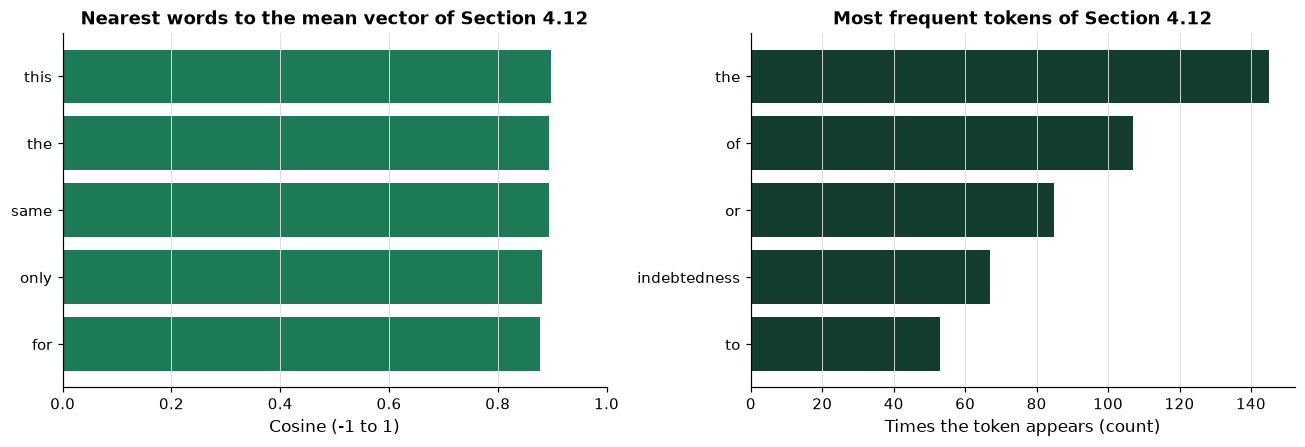

In [31]:
# source text: quoted as published
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

section_vector, section_missing = textkit.document_vectors([section_412], vectors, words)
cosine = textkit.cosine_similarity_matrix(vectors, section_vector)[:, 0]
near_section = pd.DataFrame({"word": words, "cosine": cosine}).sort_values(
    ["cosine", "word"], ascending=[False, True], kind="mergesort").head(5)
print(f"nearest words to the mean vector of Section 4.12: {', '.join(near_section['word'])}")
section_tokens = textkit.tokenize(section_412)
print(f"its most frequent tokens: {collections.Counter(section_tokens).most_common(5)}")
print(f"share of its tokens that are stop words: {sum(t in ENGLISH_STOP_WORDS for t in section_tokens) / len(section_tokens):.4f}")
print(boyd_source("4.12"))
# the nearest words to the mean vector, and the most frequent tokens, as two panels of bars
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))
left.barh(near_section["word"].to_numpy()[::-1], near_section["cosine"].to_numpy()[::-1], color=plotkit.GREEN)
left.set_title("Nearest words to the mean vector of Section 4.12")
left.set_xlabel("Cosine (-1 to 1)")
left.set_xlim(0, 1)
top_tokens = collections.Counter(section_tokens).most_common(5)
right.barh([t for t, _ in top_tokens][::-1], [n for _, n in top_tokens][::-1], color=plotkit.GREEN_DARK)
right.set_title("Most frequent tokens of Section 4.12")
right.set_xlabel("Times the token appears (count)")
for ax in (left, right):
    ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

* Left, five bars of the most ordinary words of English; right, "the" towers over the rest with 145 of the section's tokens.
* The mean of 1,840 token vectors sits nearest to "this", "the", "same", "only", "for": the most ordinary words of English. "the" alone is 145 of the section's tokens, and stop words are a share of 0.4984.
* A mean gives every token the same weight, so the frequent small words pull every section's vector toward the same place. TF-IDF weights the other way: its IDF shrinks a term that is in every document. Exercise 2 removes the stop words and measures whether the score of section 4.5 changes.

## 4.7 A Map of Words

**How it works.** A word vector has 100 numbers and a page has two axes. PCA finds the two directions along which the chosen words differ most and plots each word at its position along them. Words the vectors place close together land close together, but a lot is lost, because two directions keep only part of the variance. You control which words and how many components. What comes out is a scatter whose distances are a rough picture, and a number that says how much of the variance the picture keeps.

Q. Draw 41 words in two dimensions: rates, credit, inflation, legal terms, and five plain words as a control. Mark singular to plural as an arrow, and measure how tightly each group sits together in all 100 numbers.

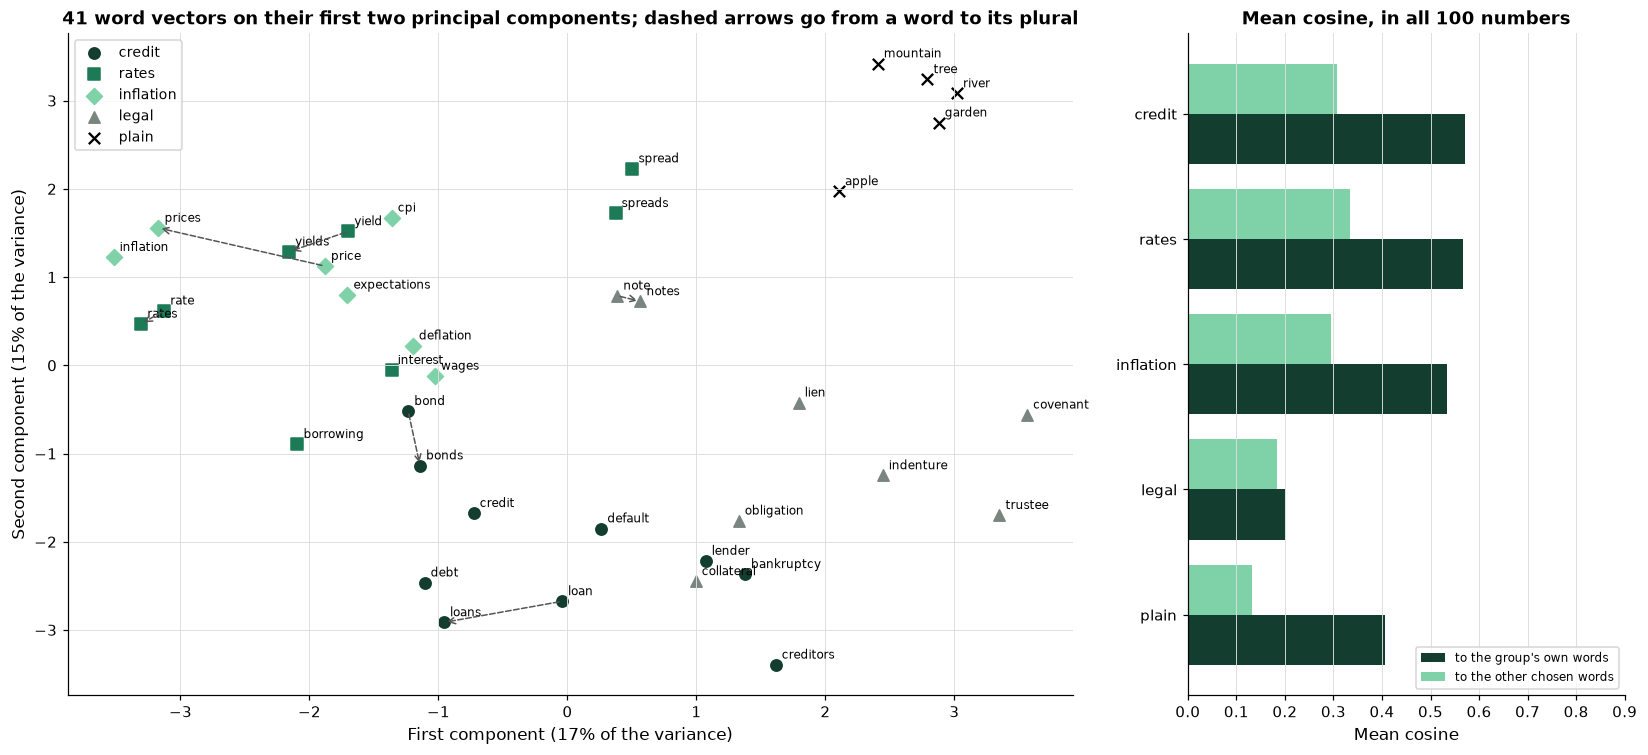

variance kept by the two components: 31%
   credit: own words 0.571, other words 0.308
    rates: own words 0.567, other words 0.333
inflation: own words 0.534, other words 0.294
    legal: own words 0.200, other words 0.185
    plain: own words 0.405, other words 0.132
cosine between the plural offsets: mean 0.208, smallest -0.065, largest 0.401


In [32]:
from matplotlib.patches import Patch

# demonstration: PCA is fitted on the 41 chosen words only to draw them in two dimensions
groups = {
    "credit": ["default", "bankruptcy", "debt", "loan", "loans", "bond", "bonds", "credit", "lender", "creditors"],
    "rates": ["rate", "rates", "yield", "yields", "interest", "borrowing", "spread", "spreads"],
    "inflation": ["inflation", "prices", "price", "deflation", "wages", "expectations", "cpi"],
    "legal": ["covenant", "indenture", "trustee", "lien", "collateral", "obligation", "note", "notes"],
    "plain": ["tree", "apple", "river", "garden", "mountain"],
}
map_words = [w for g in groups.values() for w in g]
map_label = [g for g, ws in groups.items() for _ in ws]
chosen = vectors[[position[w] for w in map_words]].astype(np.float64)
pca_map = PCA(n_components=2, random_state=SEED).fit(chosen)
points = dict(zip(map_words, pca_map.transform(chosen)))
unit = chosen / np.linalg.norm(chosen, axis=1, keepdims=True)
similarity_map = unit @ unit.T
# within a group, the mean cosine of its pairs; against the others, the mean cosine to every other chosen word
cohesion = {}
for name in groups:
    inside = [i for i, label in enumerate(map_label) if label == name]
    outside = [i for i, label in enumerate(map_label) if label != name]
    cohesion[name] = (np.mean([similarity_map[i, j] for i in inside for j in inside if i < j]), np.mean(similarity_map[np.ix_(inside, outside)]))

colours = {"credit": plotkit.GREEN_DARK, "rates": plotkit.GREEN, "inflation": plotkit.GREEN_LIGHT, "legal": plotkit.GREY, "plain": "black"}
markers = {"credit": "o", "rates": "s", "inflation": "D", "legal": "^", "plain": "x"}
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [2.3, 1]})
for name, group in groups.items():
    xy = np.array([points[w] for w in group])
    left.scatter(xy[:, 0], xy[:, 1], s=55, color=colours[name], marker=markers[name], label=name)
    for w, (x, y) in zip(group, xy):
        left.annotate(w, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=8)
# singular to plural, drawn as an arrow from each word to its plural
plurals = [("bond", "bonds"), ("loan", "loans"), ("note", "notes"), ("rate", "rates"), ("price", "prices"), ("yield", "yields")]
for a, b in plurals:
    left.annotate("", xy=points[b], xytext=points[a], arrowprops=dict(arrowstyle="->", color="#555555", linestyle="--", lw=1))
left.set_title("41 word vectors on their first two principal components; dashed arrows go from a word to its plural")
left.set_xlabel(f"First component ({pca_map.explained_variance_ratio_[0]:.0%} of the variance)")
left.set_ylabel(f"Second component ({pca_map.explained_variance_ratio_[1]:.0%} of the variance)")
left.legend(loc="best", fontsize=9)
positions_bar = np.arange(len(groups))
right.barh(positions_bar + 0.2, [cohesion[g][0] for g in groups], 0.4, color=plotkit.GREEN_DARK, label="to the group's own words")
right.barh(positions_bar - 0.2, [cohesion[g][1] for g in groups], 0.4, color=plotkit.GREEN_LIGHT, label="to the other chosen words")
right.set_yticks(positions_bar, list(groups))
right.invert_yaxis()
right.set_xlim(0, 0.9)
right.set_title("Mean cosine, in all 100 numbers")
right.set_xlabel("Mean cosine")
right.legend(loc="lower right", fontsize=8)
right.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"variance kept by the two components: {pca_map.explained_variance_ratio_.sum():.0%}")
for name in groups:
    print(f"{name:>9}: own words {cohesion[name][0]:.3f}, other words {cohesion[name][1]:.3f}")
# the six plural offsets (plural minus singular), compared with each other in all 100 numbers
offsets = np.array([vectors[position[b]].astype(np.float64) - vectors[position[a]] for a, b in plurals])
offsets = offsets / np.linalg.norm(offsets, axis=1, keepdims=True)
offset_cosines = (offsets @ offsets.T)[np.triu_indices(len(plurals), 1)]
print(f"cosine between the plural offsets: mean {offset_cosines.mean():.3f}, smallest {offset_cosines.min():.3f}, largest {offset_cosines.max():.3f}")

* The two components keep 31% of the variance of the 41 vectors, so the map is a rough picture. The credit, rates, and inflation words sit together: the mean cosine inside each group is 0.57, 0.57, and 0.53, against 0.31, 0.33, and 0.29 to the other chosen words.
* The legal words do not: 0.20 inside the group against 0.18 outside. GloVe was trained on general English, where "covenant", "lien", and "trustee" are rare words with scattered company. The five plain words, a control, hold together (0.41) and sit far from the rest (0.13).
* The six dashed arrows are not parallel. The cosine between the plural offsets averages 0.21 and the smallest is -0.07: singular to plural is a direction only roughly in these vectors, which is why section 4.4's arithmetic returns a nearest word and not a certain one.

Q. Where do vectors like these come from? Count, in the indenture, how often words occur near each other.

## 4.8 Where Word Vectors Come From

**How it works.** Word2Vec and GloVe start from one idea: a word is known by the company it keeps. GloVe counts, over a large body of text, how often every pair of words occurs close together, and fits a vector for each word so that the dot product of two vectors tracks the log of their count. Word2Vec reaches a similar place by another road: a small network learns to predict the words around each word, and the network's weights become the vectors. A count-based version fits in a few lines. Count the pairs within a window, keep the pairs that occur more often than chance would predict (positive pointwise mutual information), and squeeze the table to a few dozen columns with a singular value decomposition. You control the window, the vocabulary, and the number of dimensions. What comes out is one short vector per word of that text.

Q. Count how often ten words occur within four positions of each other in the indenture, and draw the counts.

content tokens: 30,525; vocabulary (30 or more times): 207; pairs counted: 150,116


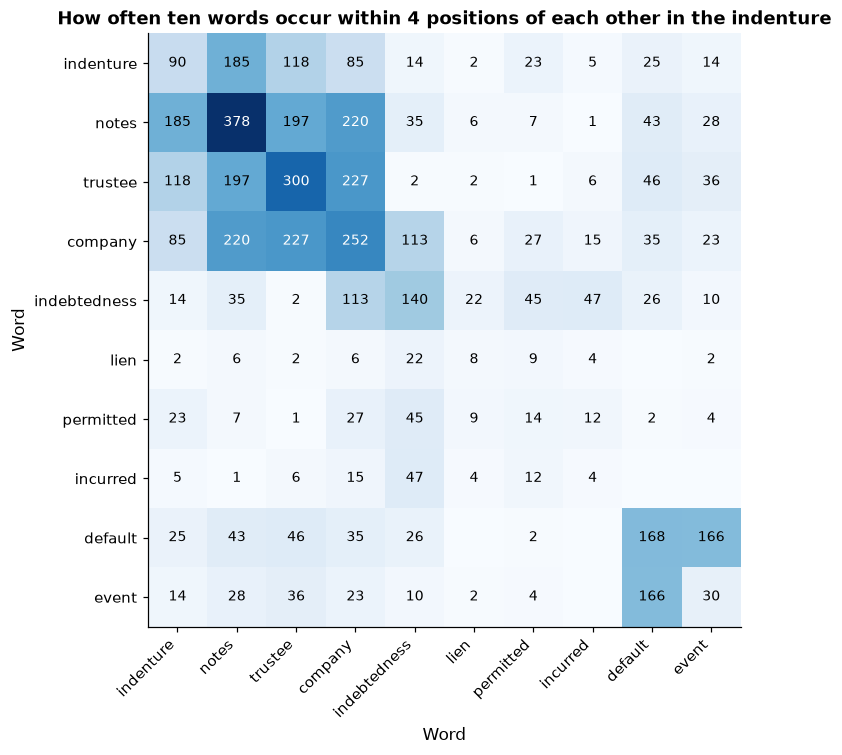

the largest count among these pairs: 378
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495.


In [33]:
import collections
import re

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def content_tokens(text):
    """The tokens of a text without stop words and number-only tokens: the pieces the pairs are counted from."""
    return [t for t in textkit.tokenize(text) if t not in ENGLISH_STOP_WORDS and not re.fullmatch(r"[0-9]+(?:[-'.][0-9]+)*", t)]


def count_pairs(tokens, vocabulary, window):
    """How often each pair of vocabulary words occurs within window positions of each other: a square table."""
    index = {word: row for row, word in enumerate(vocabulary)}
    ids = [index[t] for t in tokens if t in index]
    table = np.zeros((len(vocabulary), len(vocabulary)))
    for a in range(len(ids)):
        # the neighbours of position a: up to window positions before it and after it
        for b in range(max(0, a - window), min(len(ids), a + window + 1)):
            if a != b:
                table[ids[a], ids[b]] += 1
    return table


def svd_vectors(table, dimensions):
    """Positive pointwise mutual information of a pair table, squeezed to a few columns by a singular value decomposition."""
    total = table.sum()
    share = table.sum(axis=1) / total
    with np.errstate(divide="ignore", invalid="ignore"):
        ppmi = np.maximum(np.log(table / total / np.outer(share, share)), 0)
    ppmi[~np.isfinite(ppmi)] = 0
    left, strength, _ = np.linalg.svd(ppmi)
    return left[:, :dimensions] * np.sqrt(strength[:dimensions])


# the indenture's content tokens, and every token seen at least 30 times as the vocabulary
indenture_text = Path("course7_indentures/boyd_2021.txt").read_text(encoding="utf-8")
own_tokens = content_tokens(indenture_text)
own_counts = collections.Counter(own_tokens)
own_vocabulary = [w for w, n in own_counts.most_common() if n >= 30]
# every pair of vocabulary words within 4 positions of each other, counted once for each order
pair_counts = count_pairs(own_tokens, own_vocabulary, window=4)
print(f"content tokens: {len(own_tokens):,}; vocabulary (30 or more times): {len(own_vocabulary)}; pairs counted: {int(pair_counts.sum()):,}")
shown = ["indenture", "notes", "trustee", "company", "indebtedness", "lien", "permitted", "incurred", "default", "event"]
grid = pair_counts[np.ix_([own_vocabulary.index(w) for w in shown], [own_vocabulary.index(w) for w in shown])]
fig, ax = plt.subplots(figsize=(8.5, 7))
ax.imshow(grid, cmap="Blues")
for r in range(len(shown)):
    for c in range(len(shown)):
        if grid[r, c] > 0:
            ax.text(c, r, f"{int(grid[r, c])}", ha="center", va="center", fontsize=9, color="white" if grid[r, c] > grid.max() * 0.55 else "black")
ax.set_xticks(range(len(shown)), shown, rotation=45, ha="right")
ax.set_yticks(range(len(shown)), shown)
ax.set_title("How often ten words occur within 4 positions of each other in the indenture")
ax.set_xlabel("Word")
ax.set_ylabel("Word")
ax.grid(False)
plt.tight_layout()
plt.show()
print(f"the largest count among these pairs: {int(grid.max())}")
print(boyd_source())

* 30,525 content tokens (stop words and number-only tokens left out, as on day 1), a vocabulary of 207 words seen at least 30 times, and 150,116 pairs. The largest count among the ten words shown is 378. "indebtedness" sits beside "permitted", "lien", and "incurred": the words of Section 4.12.

Q. Squeeze the pair counts to 30 numbers per word, and compare the nearest words with GloVe's, on the same vocabulary.

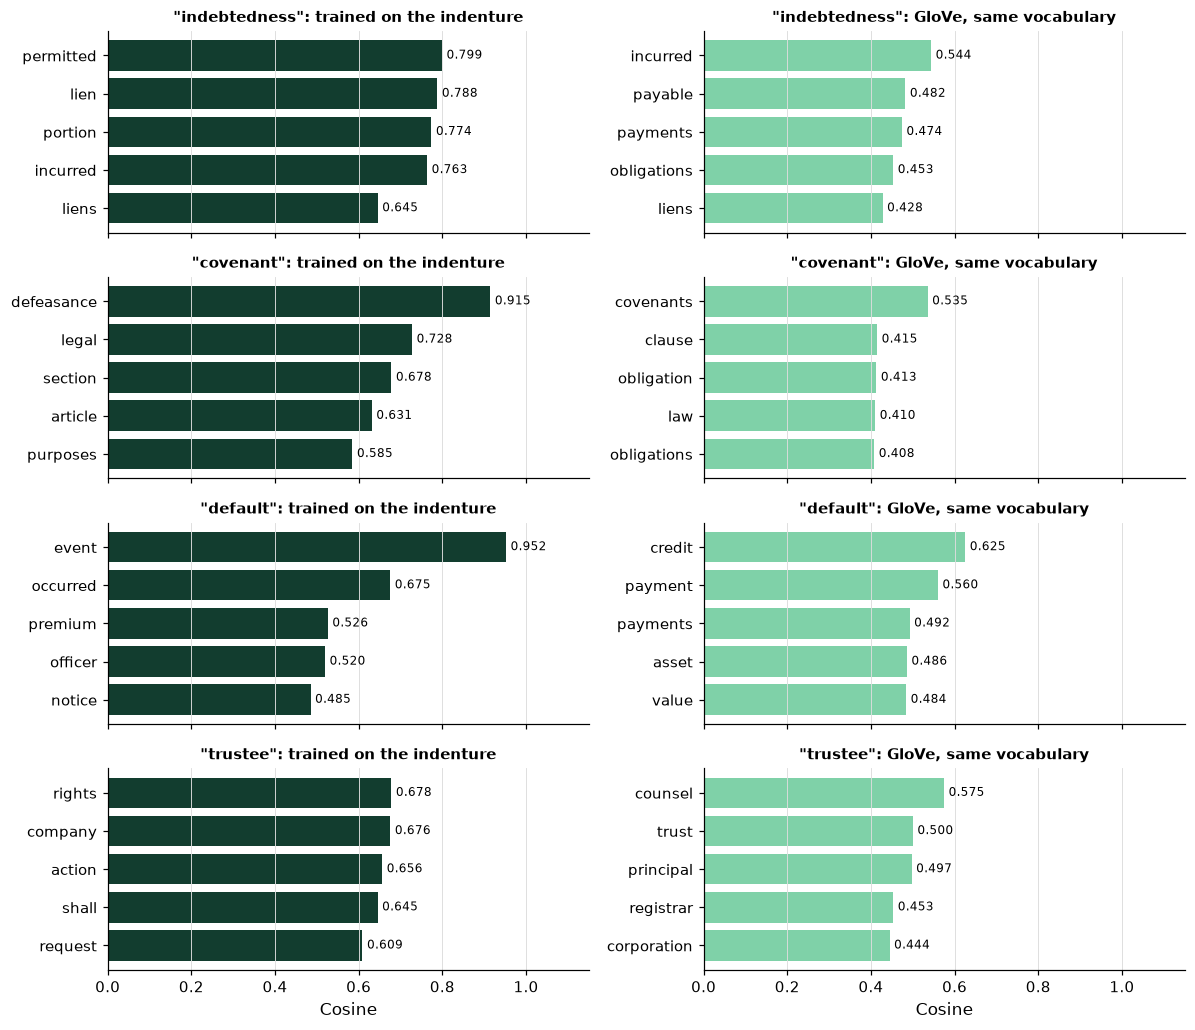

 indebtedness indenture: permitted 0.799, lien 0.788, portion 0.774, incurred 0.763, liens 0.645
              GloVe:     incurred 0.544, payable 0.482, payments 0.474, obligations 0.453, liens 0.428
     covenant indenture: defeasance 0.915, legal 0.728, section 0.678, article 0.631, purposes 0.585
              GloVe:     covenants 0.535, clause 0.415, obligation 0.413, law 0.410, obligations 0.408
      default indenture: event 0.952, occurred 0.675, premium 0.526, officer 0.520, notice 0.485
              GloVe:     credit 0.625, payment 0.560, payments 0.492, asset 0.486, value 0.484
      trustee indenture: rights 0.678, company 0.676, action 0.656, shall 0.645, request 0.609
              GloVe:     counsel 0.575, trust 0.500, principal 0.497, registrar 0.453, corporation 0.444
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495.


In [34]:
# 30 numbers per word from the pair counts of the indenture alone, then the five nearest words of four words, beside GloVe's
own_vectors = svd_vectors(pair_counts, 30)
queries = ["indebtedness", "covenant", "default", "trustee"]
glove_words = [w for w in own_vocabulary if w in position]
glove_rows = vectors[[position[w] for w in glove_words]]
own_near = {q: textkit.nearest_words(own_vectors, own_vocabulary, q, k=5) for q in queries}
glove_near = {q: textkit.nearest_words(glove_rows, glove_words, q, k=5) for q in queries}
fig, axes = plt.subplots(4, 2, figsize=(11, 9.5), sharex=True)
for row, q in enumerate(queries):
    for col, (near, title, colour) in enumerate([(own_near[q], "trained on the indenture", plotkit.GREEN_DARK), (glove_near[q], "GloVe, same vocabulary", plotkit.GREEN_LIGHT)]):
        ax = axes[row, col]
        ax.barh(near.index[::-1], near.to_numpy()[::-1], color=colour)
        ax.bar_label(ax.containers[0], fmt="%.3f", padding=3, fontsize=8)
        ax.set_title(f'"{q}": {title}', fontsize=10)
        ax.set_xlim(0, 1.15)
        ax.grid(axis="y", visible=False)
for ax in axes[-1]:
    ax.set_xlabel("Cosine")
plt.tight_layout()
plt.show()
for q in queries:
    print(f"{q:>13} indenture: " + ", ".join(f"{w} {c:.3f}" for w, c in own_near[q].items()))
    print(f"{'':>13} GloVe:     " + ", ".join(f"{w} {c:.3f}" for w, c in glove_near[q].items()))
print(boyd_source())

* **"indebtedness"**: the indenture's own vectors put "permitted", "lien", "portion", "incurred" nearest, the words around it in Section 4.12; GloVe puts "incurred", "payable", "payments", "obligations", general words of debt.
* **"covenant"**: defeasance at 0.915, because the indenture says "Legal Defeasance and Covenant Defeasance" (15 times for the second phrase). GloVe's nearest is "covenants". **"default"**: the indenture's is "event" (0.952), from "Event of Default"; GloVe's is "credit".
* Vectors learned from 30,525 tokens reflect that one document's phrases, and GloVe reflects general English: neither is right, and each is a description of the text it was counted from. This is why a firm trains vectors on its own text only when it has a lot of it. The indenture's vectors rest on 207 words; they are an illustration of the method, not a tool.

## Excel Side by Side

Excel has no word vectors and no embedding model: the numbers come from GloVe's file. Once the numbers are in a sheet, though, every comparison of today is a formula Excel has. Each formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-08) on today's own numbers: the 100 numbers of "bond" in A1:A100, "bonds" in B1:B100, "covenant" in C1:C100, the vectors of the five tokens of "the company may incur indebtedness" in D1:H100 (one token per column), and five words typed as text in J1:J5 with the first number of each one's vector beside it in K1:K5.

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| Cosine of two words | `textkit.cosine_similarity_matrix(a, b)` | `=SUMPRODUCT(A1:A100,B1:B100)/(SQRT(SUMSQ(A1:A100))*SQRT(SUMSQ(B1:B100)))` | 0.837417714032 |
| The same, "bond" and "covenant" | as above | `=SUMPRODUCT(A1:A100,C1:C100)/(SQRT(SUMSQ(A1:A100))*SQRT(SUMSQ(C1:C100)))` | 0.026505297967 |
| Length of a vector | `np.linalg.norm(bond)` | `=SQRT(SUMSQ(A1:A100))` | 5.856637530533 |
| Mean of word vectors, first number | `textkit.document_vectors(...)[0][0, 0]` | `=AVERAGE(D1:H1)` | 0.035292808712 |
| Mean of word vectors, last number | `textkit.document_vectors(...)[0][0, -1]` | `=AVERAGE(D100:H100)` | -0.203987997770 |
| Find a word in a list | `"Bonds" in position` is `False` | `=MATCH("Bonds",J1:J5,0)` | 2 |
| A word's number, by lookup | `vectors[position["bonds"]][0]` | `=XLOOKUP("Bonds",J1:J5,K1:K5)` | 1.056499958038 |
| Exact comparison | `"Bonds" == "bonds"` is `False` | `=EXACT("Bonds",J2)` | FALSE |

**Cosine is SUMPRODUCT over two lengths.** `SUMPRODUCT(A1:A100,B1:B100)` is the dot product: each number of "bond" times the same row of "bonds", added up. `SQRT(SUMSQ(A1:A100))` is the length of a vector, the square root of the sum of its squares, the same number as `np.linalg.norm`. Divide the dot product by the two lengths and Excel returns the cosine, equal to Python's within 1e-12 for both pairs.

**A document vector is AVERAGE across a row.** With one token's vector per column, `AVERAGE(D1:H1)` is the mean of the five tokens' first numbers, and filling it down 100 rows gives the whole mean vector: what `document_vectors` returns, equal within 1e-12 in the first and the last row.

**Excel's lookups ignore capitals, Python's do not.** `MATCH("Bonds",J1:J5,0)` finds "bonds" in the second row, and `XLOOKUP` returns that row's number, although the list holds only lower-case words: Excel's exact match does not compare capitals. `EXACT` does, and returns FALSE. In Python a dictionary lookup is exact, so "Bonds" is not found, which is why `document_vectors` lower-cases every token first, and why the AI check at the end of the notebook goes wrong.

**Today's charts in Excel.** The bars of cosines, neighbours, and counts are bar charts, the paired bars of F1 and recall by item are a clustered column chart, the two principal components would be two columns drawn as an XY scatter chart, and the confusion heatmaps are a colour scale from Conditional Formatting on a table of counts.

Q. Do Excel's numbers equal Python's on the same vectors?

In [35]:
# Excel's results, from the course's Excel check, beside Python's on the same numbers
bonds_vector, covenant_vector = vectors[position["bonds"]], vectors[position["covenant"]]
sentence_vector, _ = textkit.document_vectors(["the company may incur indebtedness"], vectors, words)
excel = {"cosine bond and bonds": 0.8374177140324088,
         "cosine bond and covenant": 0.026505297967434765,
         "length of bond": 5.856637530532682,
         "AVERAGE, first row": 0.035292808711528775,
         "AVERAGE, last row": -0.20398799777030946,
         "XLOOKUP of Bonds": 1.05649995803833}
python = {"cosine bond and bonds": textkit.cosine_similarity_matrix(bond[None, :], bonds_vector[None, :])[0, 0],
          "cosine bond and covenant": textkit.cosine_similarity_matrix(bond[None, :], covenant_vector[None, :])[0, 0],
          "length of bond": np.linalg.norm(bond.astype(np.float64)),
          "AVERAGE, first row": sentence_vector[0, 0],
          "AVERAGE, last row": sentence_vector[0, -1],
          "XLOOKUP of Bonds": float(vectors[position["bonds"]][0])}
side_by_side = pd.DataFrame({"Excel": excel, "Python": python})
side_by_side["within 1e-12"] = (side_by_side["Excel"] - side_by_side["Python"]).abs() <= 1e-12
print(side_by_side.to_string(float_format=lambda x: f"{x:.12f}"))

                                   Excel          Python  within 1e-12
cosine bond and bonds     0.837417714032  0.837417714032          True
cosine bond and covenant  0.026505297967  0.026505297967          True
length of bond            5.856637530533  5.856637530533          True
AVERAGE, first row        0.035292808712  0.035292808712          True
AVERAGE, last row        -0.203987997770 -0.203987997770          True
XLOOKUP of Bonds          1.056499958038  1.056499958038          True


* Every row within 1e-12. The cosine, the length, and the mean are the same arithmetic in both; what Excel cannot do is make the vectors, and what Python will not do for you is ignore capitals.

## Save the Day with Git

Today's Git step reads the history back: three commits, then `git log --oneline --stat -3`, which lists the last three commits with the files each one changed.

Q. Make the work folder a repository.

In [36]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [37]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course7_04_ty6c5cou and nowhere else


Q. Write the `.gitignore` of day 1 and commit it with Course 4's `mlkit.py`.

In [38]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx
.env
cache/

Writing .gitignore


In [39]:
!git -C "{work}" add .gitignore mlkit.py
!git -C "{work}" commit -q -m "Start the day: .gitignore and Course 4's mlkit, unchanged"

Q. Commit today's two textkit files.

In [40]:
!git -C "{work}" add textkit.py test_textkit.py
!git -C "{work}" commit -q -m "textkit day 4: load_word_vectors, nearest_words, document_vectors, 25 tests"

Q. Write the experiment log, `results.csv`, as day 3 did, with the three models of section 4.5 on the validation rows, and commit it.

model,rows,macro_f1,accuracy,recall_1_03,recall_2_04,n
majority_item,validation 2024,0.0297,0.1350,0.0000,0.0000,741
tfidf_logistic,validation 2024,0.9269,0.9298,0.8800,0.9200,741
glove_mean_logistic,validation 2024,0.8830,0.8866,0.8800,0.8000,741



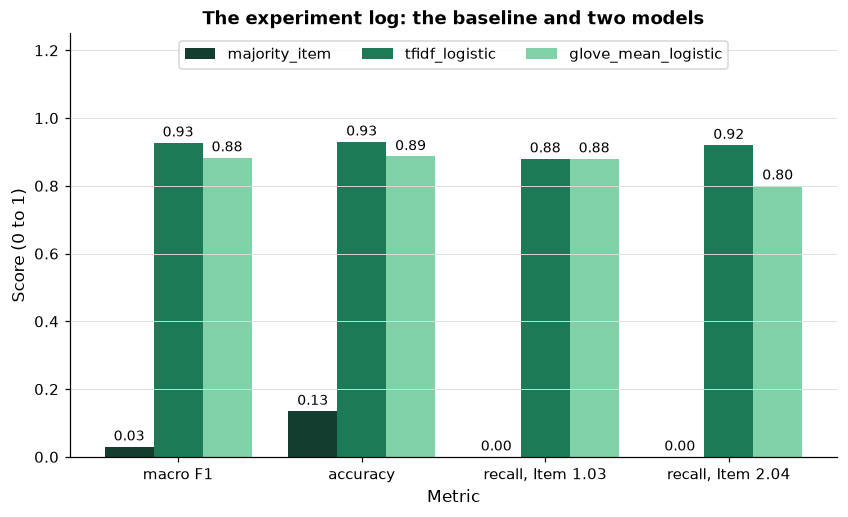

,rows,macro_f1,accuracy,recall_1_03,recall_2_04,n
model,,,,,,
majority_item,validation 2024,0.0297,0.1350,0.0000,0.0000,741
tfidf_logistic,validation 2024,0.9269,0.9298,0.8800,0.9200,741
glove_mean_logistic,validation 2024,0.8830,0.8866,0.8800,0.8000,741


In [41]:
# one row per model on the 2024 validation sections, 4 decimals, LF line endings
results = pd.DataFrame([
    {"model": "majority_item", "rows": "validation 2024",
     "macro_f1": textkit.item_report(valid["item"], [majority] * len(valid), items).loc["macro", "f1"],
     "accuracy": (valid["item"] == majority).mean(), "recall_1_03": 0.0, "recall_2_04": 0.0, "n": len(valid)},
    {"model": "tfidf_logistic", "rows": "validation 2024", "macro_f1": report_tfidf.loc["macro", "f1"],
     "accuracy": (tfidf_model.predict(valid["text"]) == valid["item"]).mean(),
     "recall_1_03": report_tfidf.loc["1.03", "recall"], "recall_2_04": report_tfidf.loc["2.04", "recall"],
     "n": len(valid)},
    {"model": "glove_mean_logistic", "rows": "validation 2024", "macro_f1": report_glove.loc["macro", "f1"],
     "accuracy": (glove_model.predict(X_valid) == valid["item"]).mean(),
     "recall_1_03": report_glove.loc["1.03", "recall"], "recall_2_04": report_glove.loc["2.04", "recall"],
     "n": len(valid)}])
results.to_csv("results.csv", index=False, float_format="%.4f", lineterminator="\n")
print(Path("results.csv").read_text(encoding="utf-8"))
# the log as bars (metrics across, models in the legend) and as a table with the baseline row
log_view = results.set_index("model")
metric_names = {"macro_f1": "macro F1", "accuracy": "accuracy", "recall_1_03": "recall, Item 1.03", "recall_2_04": "recall, Item 2.04"}
ax = plotkit.bars(log_view[list(metric_names)].rename(columns=metric_names).T, "The experiment log: the baseline and two models",
                  "Score (0 to 1)", fmt="{:.2f}")
ax.set_xlabel("Metric")
ax.set_ylim(0, 1.25)
ax.legend(ncol=3, loc="upper center")
plt.show()
plotkit.styled(log_view, list(metric_names), f"The experiment log, scored on the {len(valid)} validation sections; the first row is "
               "the majority-item baseline", fmt="{:.4f}")

In [42]:
!git -C "{work}" add results.csv
!git -C "{work}" commit -q -m "Log three models of the 8-K items on the 2024 validation sections"
!git -C "{work}" log --oneline --stat -3

c5a7bfc Log three models of the 8-K items on the 2024 validation sections
 results.csv | 4 ++++
 1 file changed, 4 insertions(+)
66054f7 textkit day 4: load_word_vectors, nearest_words, document_vectors, 25 tests
 test_textkit.py | 251 ++++++++++++++++++++++++++++++++++++
 textkit.py      | 393 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 2 files changed, 644 insertions(+)
04f76de Start the day: .gitignore and Course 4's mlkit, unchanged
 .gitignore |   5 +
 mlkit.py   | 568 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 2 files changed, 573 insertions(+)


* The first group of bars is the baseline, near 0 on every metric but accuracy; in the macro F1 group the TF-IDF bar, {r4(TFIDF_F1)}, is taller than the mean-vector bar, {r4(GLOVE_F1)}.
* `--oneline` prints each commit as its short hash and its message; `--stat` adds the files each commit changed with a bar of added lines; `-3` stops after three. Read it from the top: the newest commit first.
* `results.csv` is the experiment log: a row per model, with the rows it was scored on. Days 7 and 10 add their models to the log.

## Bring It Home

Add today's three functions to your own `textkit.py` in `my_bondmath`. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and open the two files.

```powershell
Set-Location "$HOME\projects\my_bondmath"
code textkit.py
code test_textkit.py
```

**Step 2.** Paste the code of the three `%%writefile -a textkit.py` cells (sections 4.1, 4.2, and 4.3), without their first lines, at the end of `textkit.py`, one after the other; do the same for the two `test_textkit.py` cells. Save both.

**Step 3.** Run the tests. They use the five-word table typed in the test file, so they need no data file.

```powershell
python -m pytest -q test_textkit.py
```

The last line says `25 passed`.

**Step 4.** Read what changed, commit, and read the history back.

```powershell
git diff --stat
git add textkit.py test_textkit.py
git commit -m "textkit day 4: load_word_vectors, nearest_words, document_vectors, 25 tests"
git log --oneline --stat -3
```

To use the vectors on your own machine, give `textkit.load_word_vectors` the path of `course7_glove_6b_100d.npz` in the `data` folder of your copy of the course repo.

**In Colab**, download `textkit.py` and `test_textkit.py` from the work folder under `/tmp` in the file browser.

## You Can Now

* Load pretrained word vectors with `load_word_vectors`, and say what one row of numbers is and is not.
* Measure the cosine between two words, and list a word's nearest words with `nearest_words`, ties broken by the word.
* Say why "covenant", "notes", and "lien" land among general English words, and why uncased vectors cannot tell a defined term from the ordinary word.
* Count the tokens of a document that have no vector, and say why possessives miss.
* Turn texts into mean vectors with `document_vectors`, fit a classifier on them, and compare it with TF-IDF on the same validation rows.
* Say what an average loses: word order and each word's weight.
* Draw word vectors in two dimensions, and say how vectors come from counts of words near each other.
* Compute a cosine in Excel with `SUMPRODUCT` and `SQRT(SUMSQ())`, a mean vector with `AVERAGE`, and say why Excel's `MATCH` finds "Bonds" when Python does not.

Next, day 5: a case study on the wording of FOMC statements over time.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

The exercises use the GloVe vectors, the 8-K sections (training and validation rows only), and the Boyd indenture, described only. Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the vectors, the 8-K split, and Section 4.12 of the indenture, and defines `check`, a small function that marks your answers.

In [43]:
import collections

from sklearn.linear_model import LogisticRegression

vectors, words = textkit.load_word_vectors("course7_glove_6b_100d.npz")
position = {word: row for row, word in enumerate(words)}
eightk = pd.read_csv("course7_8k_items.csv", dtype={"item": str})
# the 2025 rows are closed: the third part is kept aside and never used
train, valid, _closed = textkit.date_split(eightk, "filed", "2023-12-31", "2024-12-31")
items = list(textkit.ITEM_TITLES)
indenture = Path("course7_indentures/boyd_2021.txt").read_text(encoding="utf-8")
sections = textkit.find_sections(indenture).set_index("number")
section_412 = indenture[sections.loc["4.12", "start"]:sections.loc["4.12", "end"]]

# section 4.8's helpers and the indenture's vocabulary, for Exercise 4
import re

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def content_tokens(text):
    """The tokens of a text without stop words and number-only tokens: the pieces the pairs are counted from."""
    return [t for t in textkit.tokenize(text) if t not in ENGLISH_STOP_WORDS and not re.fullmatch(r"[0-9]+(?:[-'.][0-9]+)*", t)]


def count_pairs(tokens, vocabulary, window):
    """How often each pair of vocabulary words occurs within window positions of each other: a square table."""
    index = {word: row for row, word in enumerate(vocabulary)}
    ids = [index[t] for t in tokens if t in index]
    table = np.zeros((len(vocabulary), len(vocabulary)))
    for a in range(len(ids)):
        # the neighbours of position a: up to window positions before it and after it
        for b in range(max(0, a - window), min(len(ids), a + window + 1)):
            if a != b:
                table[ids[a], ids[b]] += 1
    return table


def svd_vectors(table, dimensions):
    """Positive pointwise mutual information of a pair table, squeezed to a few columns by a singular value decomposition."""
    total = table.sum()
    share = table.sum(axis=1) / total
    with np.errstate(divide="ignore", invalid="ignore"):
        ppmi = np.maximum(np.log(table / total / np.outer(share, share)), 0)
    ppmi[~np.isfinite(ppmi)] = 0
    left, strength, _ = np.linalg.svd(ppmi)
    return left[:, :dimensions] * np.sqrt(strength[:dimensions])

own_tokens = content_tokens(indenture)
own_vocabulary = [w for w, n in collections.Counter(own_tokens).most_common() if n >= 30]


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

### Exercise 1

Q. Which five words are nearest to "indenture"? Store them, in order, as a list in **ex1_indenture**. Which word is nearest to "trustee", and at what cosine? Store the word in **ex1_trustee_top** and the cosine in **ex1_trustee_cosine** (a `float`).

In [44]:
ex1_indenture = ...
ex1_trustee_top = ...
ex1_trustee_cosine = ...

In [45]:
check("Exercise 1 nearest to indenture", ex1_indenture, ['indentures', 'exclusivity', 'seven-year', 'noncompete', 'ten-year'])
check("Exercise 1 nearest to trustee", ex1_trustee_top, 'trustees')
check("Exercise 1 its cosine", ex1_trustee_cosine, 0.7656753396442938)

Exercise 1 nearest to indenture: not attempted yet
Exercise 1 nearest to trustee: not attempted yet
Exercise 1 its cosine: not attempted yet


### Exercise 2

Section 4.6 found that a mean vector leans toward the stop words. Remove them and measure the change.

Q. Rebuild each training and validation section from its `textkit.tokenize` tokens with scikit-learn's `ENGLISH_STOP_WORDS` left out (joined by spaces), take `document_vectors` of the rebuilt texts, fit `LogisticRegression(max_iter=10_000, tol=1e-10, random_state=SEED)` on the training vectors, and store the validation macro F1 from `textkit.item_report` in **ex2_macro_f1** (a `float`).

In [46]:
ex2_macro_f1 = ...

In [47]:
check("Exercise 2 macro F1 without stop words", ex2_macro_f1, 0.8856803711434276)

Exercise 2 macro F1 without stop words: not attempted yet


### Exercise 3

Q. Add a function to your module. `vector_norms(vectors, words, chosen)` returns a Series, indexed by word in the order chosen, of the length of each chosen word's vector (the square root of the sum of its squares, Excel's `SQRT(SUMSQ())`), as `float64`; it raises `KeyError` naming the first chosen word not in the list, and `ValueError` if `chosen` is empty. Write the docstring first. Then add `test_vector_norms_hand`, which uses `small_vectors()` to check the lengths of "tree" (1.0) and "bonds" (the square root of 0.82) and that "covenant" raises. Run pytest, reload the module, and store the length of "the" in **ex3_the** and the longest of "the", "bond", "inflation", "indenture" in **ex3_longest**.

Write the function in the cell that starts with `%%writefile -a textkit.py` and the test in the one that starts with `%%writefile -a test_textkit.py`, and run each of those cells once.

In [48]:
%%writefile -a textkit.py


# Exercise 3: write vector_norms(vectors, words, chosen) below this line

Appending to textkit.py


In [49]:
%%writefile -a test_textkit.py


# Exercise 3: write test_vector_norms_hand() below this line

Appending to test_textkit.py


In [50]:
# run pytest, reload the module, then run your function
ex3_the = ...
ex3_longest = ...

In [51]:
check("Exercise 3 the length of the", ex3_the, 5.821153648478409)
check("Exercise 3 the longest", ex3_longest, 'inflation')

Exercise 3 the length of the: not attempted yet
Exercise 3 the longest: not attempted yet


### Exercise 4

Section 4.8 built small word vectors from pair counts with a window of 4. The window is a setting, like those of day 2.

Q. The helper functions of section 4.8 (`content_tokens`, `count_pairs`, `svd_vectors`) and the indenture's vocabulary (`own_vocabulary`, 207 words) are loaded for you. Count the pairs with a window of 1 (adjacent words only) and with a window of 8, squeeze each to 30 numbers, and find the nearest word to "indebtedness" for each. Store a dictionary keyed by the window, with the nearest word and its cosine to 3 decimals as a tuple, in **ex4_nearest**. Say what the window changed.

In [52]:
ex4_nearest = ...

In [53]:
check("Exercise 4 the nearest words by window", ex4_nearest, {1: ('item', 0.712), 8: ('incurred', 0.726)})

Exercise 4 the nearest words by window: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that turns a text into its mean GloVe vector and reports how much of the text has no vector, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
The mean GloVe vector of a text, and the share of its tokens with no vector.

    Inputs: text; vectors and words, as textkit.load_word_vectors returns them.
    Output: (vector, missing_share). GloVe is uncased, so every token is looked up in lower case. The vector is
    the mean of the vectors of the tokens found; missing_share is the share of ALL the text's tokens that have no
    vector, so a capitalised word counts like any other.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns a plausible vector and share, and contains one bug.

In [54]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def text_vector(text, vectors, words):
    """The mean GloVe vector of a text, and the share of its tokens with no vector.

    Inputs: text; vectors and words, as textkit.load_word_vectors returns them.
    Output: (vector, missing_share). GloVe is uncased, so every token is looked up in lower case. The vector is
    the mean of the vectors of the tokens found; missing_share is the share of ALL the text's tokens that have no
    vector, so a capitalised word counts like any other.
    """
    position = {w: i for i, w in enumerate(words)}
    # the tokens of the text that have a vector
    tokens = [t for t in textkit.tokenize(text, lower=False) if t in position]
    vector = np.asarray(vectors)[[position[t] for t in tokens]].astype(np.float64).mean(axis=0)
    # the share of tokens with no vector
    missing_share = sum(t not in position for t in tokens) / len(tokens)
    return vector, missing_share

Q. Before you run the next cell: on Section 4.12, what missing share does the function report, and how many of the section's tokens does its vector use?

In [55]:
# source text: quoted as published
vector, share = text_vector(section_412, vectors, words)
used = [t for t in textkit.tokenize(section_412, lower=False) if t in position]
print(f"missing share reported: {share:.4f}; tokens used: {len(used):,} of {len(textkit.tokenize(section_412)):,}")
_, true_share = textkit.document_vectors([section_412], vectors, words)
print(f"document_vectors' missing share: {true_share[0]:.4f}")
print("Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed "
      "2021-06-08, accession 0001193125-21-185495, Section 4.12.")

missing share reported: 0.0000; tokens used: 1,458 of 1,840
document_vectors' missing share: 0.0114
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 4.12.


Q. Test the function against its docstring before you trust it, on a sentence written for the test whose missing share you can count by hand.

In [56]:
# the test, written from the docstring before the code is trusted
sentence = "The Company's Notes are subject to defeasance under the Indenture."
# by hand: 10 tokens in lower case; "company's" and "defeasance" have no vector, so the share is 2 / 10
vector, share = text_vector(sentence, vectors, words)
assert abs(share - 2 / 10) < 1e-12, f"missing share {share:.4f}, by hand 0.2000"
found = [t for t in textkit.tokenize(sentence) if t in position]
assert np.allclose(vector, vectors[[position[t] for t in found]].mean(axis=0), atol=1e-6), "not the mean of the 8 found"
print(f"missing share {share:.4f}, equal to the hand count; the vector is the mean of {len(found)} tokens")

AssertionError: missing share 0.0000, by hand 0.2000

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the fixed function's missing share on Section 4.12 in **ex5_missing** (a `float`).

In [57]:
# fix the function above and run the test again, then store the answer
ex5_missing = ...

In [58]:
check("Exercise 5 the fixed missing share", ex5_missing, 0.011413043478260887)

Exercise 5 the fixed missing share: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```